# CICIOT2023 Thesis-Ready DDoS/Attack Detection Pipeline


-- CNN-only deep learning model  
-- LSTM-only deep learning model  
-- Main hybrid CNN-LSTM model with Bayesian optimization  
-- Five classical machine learning baseline models  
-- Optuna Bayesian optimization visualizations using Matplotlib so the plots show properly in Kaggle  
-- Rich thesis-useful evaluation plots, tables, confusion matrices, ROC curves, PR curves, and comparison charts  
-- Automatic saving of figures, metrics, trained models, scaler, and zipped output folder

Binary target mapping:

-- `BenignTraffic` = 0  
-- All other attack classes = 1

In [1]:
#-------------- Install required packages ---------------#

!pip install -q gdown optuna seaborn joblib


In [2]:
#-------------- Import required libraries ---------------#

import os
import gc
import json
import time
import random
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from tqdm.auto import tqdm

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import optuna
from optuna.importance import get_param_importances

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Libraries imported successfully.")
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Libraries imported successfully.
Torch version: 2.10.0+cu128
CUDA available: True


## 1. Download and Unzip Dataset

The dataset is downloaded from your Google Drive ZIP file, unzipped into `/kaggle/working/`, and the ZIP is removed after extraction.

In [3]:
#-------------- Download, unzip, and delete zip file ---------------#

import subprocess

GOOGLE_DRIVE_FILE_ID = "16ncVe5ud8PdMUXzve-O1VI08DeTJpzIh"
ZIP_NAME = "CICIOT23.zip"
DATASET_ROOT = "/kaggle/working/CICIOT23"

if not os.path.exists(DATASET_ROOT):
    print("Dataset folder not found. Downloading from Google Drive...")
    subprocess.run(["gdown", GOOGLE_DRIVE_FILE_ID, "-O", ZIP_NAME], check=True)

    print("Unzipping dataset...")
    with zipfile.ZipFile(ZIP_NAME, "r") as zip_ref:
        zip_ref.extractall(".")

    if os.path.exists(ZIP_NAME):
        os.remove(ZIP_NAME)
        print("Deleted ZIP file:", ZIP_NAME)
else:
    print("Dataset folder already exists:", DATASET_ROOT)

print("Dataset root:", DATASET_ROOT)


Dataset folder not found. Downloading from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=16ncVe5ud8PdMUXzve-O1VI08DeTJpzIh
From (redirected): https://drive.google.com/uc?id=16ncVe5ud8PdMUXzve-O1VI08DeTJpzIh&confirm=t&uuid=b635d268-feba-4421-9894-1bf2887f979c
To: /kaggle/working/CICIOT23.zip
100%|██████████| 474M/474M [00:04<00:00, 110MB/s]  


Unzipping dataset...
Deleted ZIP file: CICIOT23.zip
Dataset root: /kaggle/working/CICIOT23


In [4]:
#-------------- Verify folder structure and CSV paths ---------------#

TRAIN_PATH = os.path.join(DATASET_ROOT, "train", "train.csv")
VAL_PATH = os.path.join(DATASET_ROOT, "validation", "validation.csv")
TEST_PATH = os.path.join(DATASET_ROOT, "test", "test.csv")

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    print(path, "-->", os.path.exists(path))
    if os.path.exists(path):
        print("Size MB:", round(os.path.getsize(path) / (1024 * 1024), 2))

assert os.path.exists(TRAIN_PATH), "Train CSV was not found."
assert os.path.exists(VAL_PATH), "Validation CSV was not found."
assert os.path.exists(TEST_PATH), "Test CSV was not found."


/kaggle/working/CICIOT23/train/train.csv --> True
Size MB: 1548.24
/kaggle/working/CICIOT23/validation/validation.csv --> True
Size MB: 331.8
/kaggle/working/CICIOT23/test/test.csv --> True
Size MB: 331.84


## 2. Runtime Configuration

For the final thesis run, keep `RUN_MODE = "full"`.  
For a quick check, set `RUN_MODE = "quick"`.

Important Kaggle note: CICIOT2023 is large. The deep learning models use streaming sequence datasets. Classical ML models are trained on a configurable stratified sample to avoid notebook crashes. Increase `ML_TRAIN_SAMPLE_SIZE` if your Kaggle session has enough RAM and time.

In [5]:
#-------------- Runtime configuration ---------------#

RUN_MODE = "full"   # options: "quick", "full"

if RUN_MODE == "quick":
    MAX_TRAIN_ROWS = 300_000
    MAX_VAL_ROWS = 100_000
    MAX_TEST_ROWS = 100_000

    OPTUNA_TRIALS = 3
    OPTUNA_EPOCHS = 2
    CNN_EPOCHS = 3
    LSTM_EPOCHS = 3
    FINAL_CNN_LSTM_EPOCHS = 5

    OPTUNA_MAX_TRAIN_BATCHES = 80
    OPTUNA_MAX_VAL_BATCHES = 50
    FINAL_MAX_TRAIN_BATCHES_PER_EPOCH = 150
    FINAL_MAX_VAL_BATCHES_PER_EPOCH = 80
    MAX_EVAL_BATCHES = 120

    ML_TRAIN_SAMPLE_SIZE = 100_000
    ML_TEST_SAMPLE_SIZE = 100_000
else:
    MAX_TRAIN_ROWS = None
    MAX_VAL_ROWS = None
    MAX_TEST_ROWS = None

    OPTUNA_TRIALS = 10
    OPTUNA_EPOCHS = 3
    CNN_EPOCHS = 8
    LSTM_EPOCHS = 8
    FINAL_CNN_LSTM_EPOCHS = 15

    # Bayesian optimization is intentionally run on limited batches for practical runtime.
    # For a longer final thesis run, increase these numbers or set them to None.
    OPTUNA_MAX_TRAIN_BATCHES = 300
    OPTUNA_MAX_VAL_BATCHES = 150

    # Keep these limited by default so the notebook completes in Kaggle.
    # For a complete full-dataset epoch, set FINAL_MAX_TRAIN_BATCHES_PER_EPOCH = None.
    FINAL_MAX_TRAIN_BATCHES_PER_EPOCH = 1200
    FINAL_MAX_VAL_BATCHES_PER_EPOCH = 300
    MAX_EVAL_BATCHES = 500

    # Classical ML baselines use stratified samples for practical runtime.
    # Increase for final experiments if memory/time allows.
    ML_TRAIN_SAMPLE_SIZE = 500_000
    ML_TEST_SAMPLE_SIZE = 300_000

SEQ_LEN = 100
BATCH_SIZE = 512
NUM_WORKERS = 0

LABEL_COLUMN = "label"
BENIGN_LABEL = "BenignTraffic"

OUTPUT_DIR = "/kaggle/working/ciciot2023_thesis_outputs"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
TABLE_DIR = os.path.join(OUTPUT_DIR, "tables")

for folder in [OUTPUT_DIR, FIGURE_DIR, MODEL_DIR, TABLE_DIR]:
    os.makedirs(folder, exist_ok=True)

print("RUN_MODE:", RUN_MODE)
print("Output directory:", OUTPUT_DIR)
print("Sequence length:", SEQ_LEN)
print("Batch size:", BATCH_SIZE)
print("Optuna trials:", OPTUNA_TRIALS)
print("CNN epochs:", CNN_EPOCHS)
print("LSTM epochs:", LSTM_EPOCHS)
print("Final CNN-LSTM epochs:", FINAL_CNN_LSTM_EPOCHS)
print("ML train sample size:", ML_TRAIN_SAMPLE_SIZE)
print("ML test sample size:", ML_TEST_SAMPLE_SIZE)


RUN_MODE: full
Output directory: /kaggle/working/ciciot2023_thesis_outputs
Sequence length: 100
Batch size: 512
Optuna trials: 10
CNN epochs: 8
LSTM epochs: 8
Final CNN-LSTM epochs: 15
ML train sample size: 500000
ML test sample size: 300000


In [6]:
#-------------- Plot saving helper ---------------#

def save_fig(filename, dpi=300):
    path = os.path.join(FIGURE_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("Saved figure:", path)
    plt.show()


## 3. Load Dataset

CICIOT2023 has separate train, validation, and test CSV files.

In [7]:
#-------------- Read header and prepare feature columns ---------------#

header_cols = pd.read_csv(TRAIN_PATH, nrows=0).columns.tolist()
print("Number of columns:", len(header_cols))
print("Columns:")
for i, col in enumerate(header_cols):
    print(i, col)

FEATURE_COLUMNS = [col for col in header_cols if col != LABEL_COLUMN]
NUM_FEATURES = len(FEATURE_COLUMNS)

print("\nNumber of feature columns:", NUM_FEATURES)
print("Label column:", LABEL_COLUMN)
print("Benign label:", BENIGN_LABEL)


Number of columns: 47
Columns:
0 flow_duration
1 Header_Length
2 Protocol Type
3 Duration
4 Rate
5 Srate
6 Drate
7 fin_flag_number
8 syn_flag_number
9 rst_flag_number
10 psh_flag_number
11 ack_flag_number
12 ece_flag_number
13 cwr_flag_number
14 ack_count
15 syn_count
16 fin_count
17 urg_count
18 rst_count
19 HTTP
20 HTTPS
21 DNS
22 Telnet
23 SMTP
24 SSH
25 IRC
26 TCP
27 UDP
28 DHCP
29 ARP
30 ICMP
31 IPv
32 LLC
33 Tot sum
34 Min
35 Max
36 AVG
37 Std
38 Tot size
39 IAT
40 Number
41 Magnitue
42 Radius
43 Covariance
44 Variance
45 Weight
46 label

Number of feature columns: 46
Label column: label
Benign label: BenignTraffic


In [8]:
#-------------- Load train, validation, and test CSV files ---------------#

# All feature columns are numeric according to the exploration log, so float32 reduces memory usage.
dtype_map = {col: "float32" for col in FEATURE_COLUMNS}
dtype_map[LABEL_COLUMN] = "string"
usecols = FEATURE_COLUMNS + [LABEL_COLUMN]

def load_split(path, nrows=None, split_name=""):
    print(f"Loading {split_name}: {path}")
    df = pd.read_csv(path, usecols=usecols, dtype=dtype_map, nrows=nrows)
    print(f"{split_name} shape:", df.shape)
    return df

train_df = load_split(TRAIN_PATH, MAX_TRAIN_ROWS, "Train")
val_df = load_split(VAL_PATH, MAX_VAL_ROWS, "Validation")
test_df = load_split(TEST_PATH, MAX_TEST_ROWS, "Test")

print("\nTrain head:")
display(train_df.head())


Loading Train: /kaggle/working/CICIOT23/train/train.csv
Train shape: (5491971, 47)
Loading Validation: /kaggle/working/CICIOT23/validation/validation.csv
Validation shape: (1176851, 47)
Loading Test: /kaggle/working/CICIOT23/test/test.csv
Test shape: (1176851, 47)

Train head:


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,urg_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,757.000000,6.00,64.000000,23.671858,23.671858,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.50,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,9627.00000,374.0,1457.000000,883.202209,538.470764,944.000000,83340576.0,9.5,41.845547,761.456787,305219.312500,0.95,141.550003,DDoS-ACK_Fragmentation
1,0.000000,54.000000,6.00,64.000000,2.393046,2.393046,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.00000,54.0,54.000000,54.000000,0.000000,54.000000,83093264.0,9.5,10.392304,0.000000,0.000000,0.00,141.550003,DDoS-SYN_Flood
2,0.033982,56.779999,6.11,64.639999,1.192715,1.192715,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.99,0.99,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,572.51001,54.0,59.509998,54.753345,1.727526,54.290001,83330864.0,9.5,10.462812,2.445286,16.853117,0.19,141.550003,DDoS-PSHACK_Flood
3,0.000000,0.000000,47.00,64.000000,9.841972,9.841972,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,6216.00000,592.0,592.000000,592.000000,0.000000,592.000000,83702784.0,9.5,34.409302,0.000000,0.000000,0.00,141.550003,Mirai-greeth_flood
4,3.944828,108.000000,6.00,64.000000,0.506993,0.506993,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,567.00000,54.0,54.000000,54.000000,0.000000,54.000000,82972704.0,9.5,10.392304,0.000000,0.000000,0.00,141.550003,DoS-SYN_Flood


## 4. Dataset Inspection and Cleaning

In [9]:
#-------------- Basic cleaning report ---------------#

def basic_cleaning_report(df, name):
    print("=" * 100)
    print(name)
    print("Shape:", df.shape)
    print("Total missing values:", int(df.isnull().sum().sum()))
    print("Empty label values:", int(df[LABEL_COLUMN].astype(str).str.strip().eq("").sum()))
    numeric_inf = np.isinf(df[FEATURE_COLUMNS].to_numpy()).sum()
    print("Numeric infinity values:", int(numeric_inf))
    print("Number of original label classes:", df[LABEL_COLUMN].nunique())
    print("Top 20 original labels:")
    print(df[LABEL_COLUMN].value_counts().head(20))

basic_cleaning_report(train_df, "TRAIN DATA BEFORE CLEANING")
basic_cleaning_report(val_df, "VALIDATION DATA BEFORE CLEANING")
basic_cleaning_report(test_df, "TEST DATA BEFORE CLEANING")


TRAIN DATA BEFORE CLEANING
Shape: (5491971, 47)
Total missing values: 0
Empty label values: 0
Numeric infinity values: 0
Number of original label classes: 34
Top 20 original labels:
label
DDoS-ICMP_Flood            848088
DDoS-UDP_Flood             637558
DDoS-TCP_Flood             528499
DDoS-PSHACK_Flood          481254
DDoS-SYN_Flood             478653
DDoS-RSTFINFlood           475441
DDoS-SynonymousIP_Flood    422083
DoS-UDP_Flood              390422
DoS-TCP_Flood              314174
DoS-SYN_Flood              237573
BenignTraffic              129538
Mirai-greeth_flood         116133
Mirai-udpplain             104814
Mirai-greip_flood           88821
DDoS-ICMP_Fragmentation     53046
MITM-ArpSpoofing            36316
DDoS-UDP_Fragmentation      34169
DDoS-ACK_Fragmentation      33581
DNS_Spoofing                21214
Recon-HostDiscovery         15737
Name: count, dtype: Int64
VALIDATION DATA BEFORE CLEANING
Shape: (1176851, 47)
Total missing values: 0
Empty label values: 0
Numeric

In [10]:
#-------------- Clean feature values and labels ---------------#

def clean_split(df, name):
    df = df.copy()

    df[LABEL_COLUMN] = df[LABEL_COLUMN].astype(str).str.strip()
    df = df[df[LABEL_COLUMN].notna()]
    df = df[df[LABEL_COLUMN] != ""]

    df[FEATURE_COLUMNS] = df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    missing_before = int(df[FEATURE_COLUMNS].isnull().sum().sum())
    df[FEATURE_COLUMNS] = df[FEATURE_COLUMNS].fillna(0)
    missing_after = int(df[FEATURE_COLUMNS].isnull().sum().sum())

    print(f"{name} cleaned shape: {df.shape}")
    print(f"{name} missing numeric values before fill: {missing_before}")
    print(f"{name} missing numeric values after fill: {missing_after}")
    return df

train_df = clean_split(train_df, "Train")
val_df = clean_split(val_df, "Validation")
test_df = clean_split(test_df, "Test")


Train cleaned shape: (5491971, 47)
Train missing numeric values before fill: 0
Train missing numeric values after fill: 0
Validation cleaned shape: (1176851, 47)
Validation missing numeric values before fill: 0
Validation missing numeric values after fill: 0
Test cleaned shape: (1176851, 47)
Test missing numeric values before fill: 0
Test missing numeric values after fill: 0


In [11]:
#-------------- Convert labels to binary labels ---------------#
# BenignTraffic = 0, all other attack classes = 1

for df in [train_df, val_df, test_df]:
    df["binary_label"] = (df[LABEL_COLUMN] != BENIGN_LABEL).astype("int64")

print("Original train label distribution:")
display(train_df[LABEL_COLUMN].value_counts().to_frame("Count"))

print("\nBinary train label distribution:")
display(train_df["binary_label"].value_counts().rename(index={0: "Benign", 1: "Attack"}).to_frame("Count"))

print("\nBinary validation label distribution:")
display(val_df["binary_label"].value_counts().rename(index={0: "Benign", 1: "Attack"}).to_frame("Count"))

print("\nBinary test label distribution:")
display(test_df["binary_label"].value_counts().rename(index={0: "Benign", 1: "Attack"}).to_frame("Count"))


Original train label distribution:


,Count
label,
DDoS-ICMP_Flood,848088
DDoS-UDP_Flood,637558
DDoS-TCP_Flood,528499
DDoS-PSHACK_Flood,481254
DDoS-SYN_Flood,478653
DDoS-RSTFINFlood,475441
DDoS-SynonymousIP_Flood,422083
DoS-UDP_Flood,390422
DoS-TCP_Flood,314174



Binary train label distribution:


,Count
binary_label,
Attack,5362433
Benign,129538



Binary validation label distribution:


,Count
binary_label,
Attack,1149332
Benign,27519



Binary test label distribution:


,Count
binary_label,
Attack,1149142
Benign,27709


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/top_25_original_train_classes.png


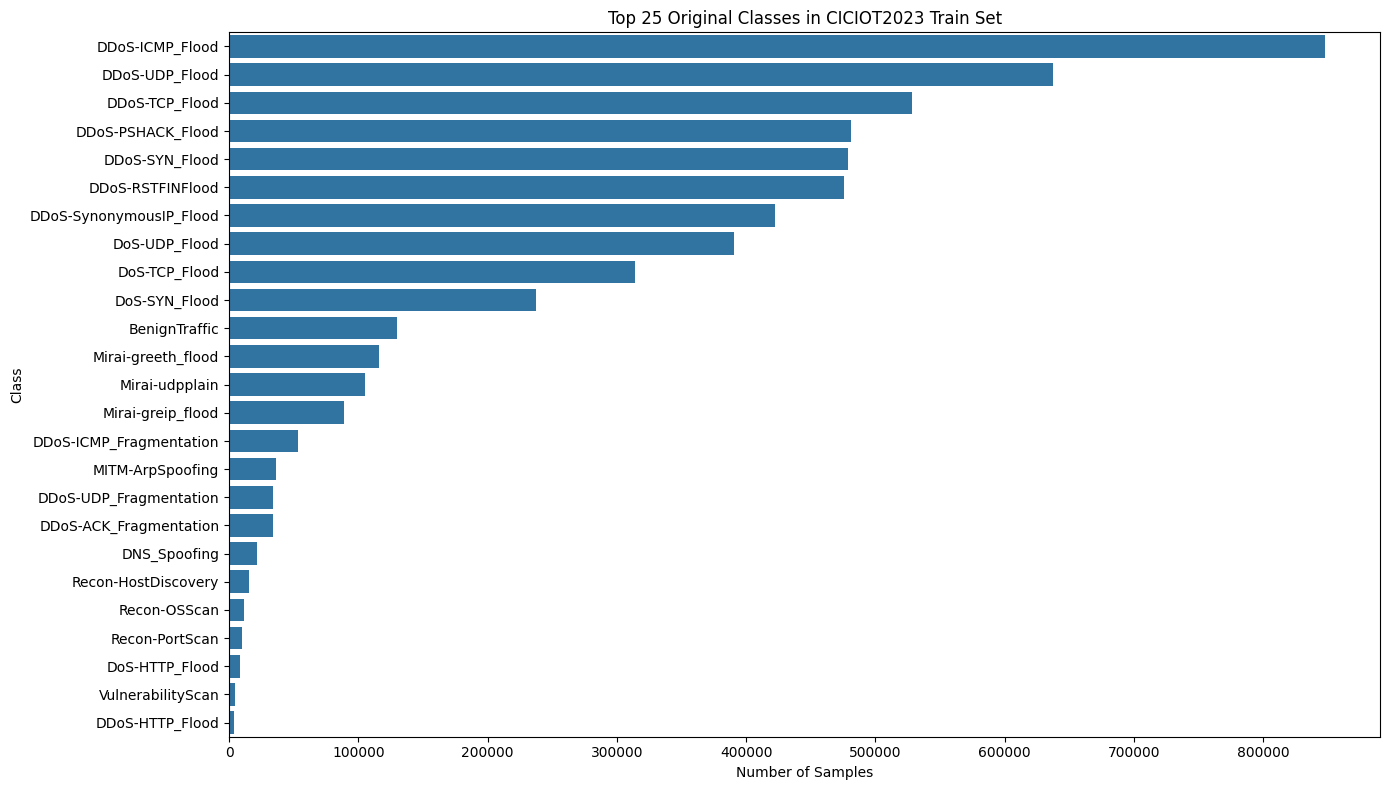

In [12]:
#-------------- Plot original class distribution ---------------#

class_counts = train_df[LABEL_COLUMN].value_counts()
class_counts_df = class_counts.reset_index()
class_counts_df.columns = ["Class", "Count"]
class_counts_df.to_csv(os.path.join(TABLE_DIR, "original_train_class_distribution.csv"), index=False)

plt.figure(figsize=(14, 8))
sns.barplot(data=class_counts_df.head(25), x="Count", y="Class")
plt.title("Top 25 Original Classes in CICIOT2023 Train Set")
plt.xlabel("Number of Samples")
plt.ylabel("Class")
save_fig("top_25_original_train_classes.png")


,Class,Count,Percentage
0,Benign,129538,2.35868
1,Attack,5362433,97.64132


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/binary_train_class_distribution_bar.png


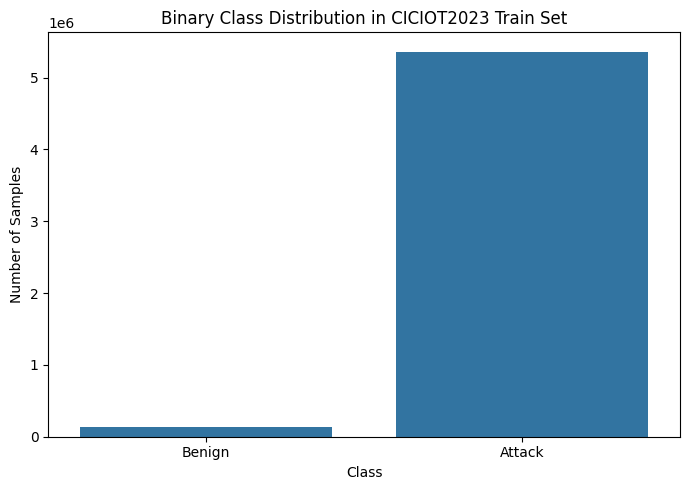

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/binary_train_class_distribution_pie.png


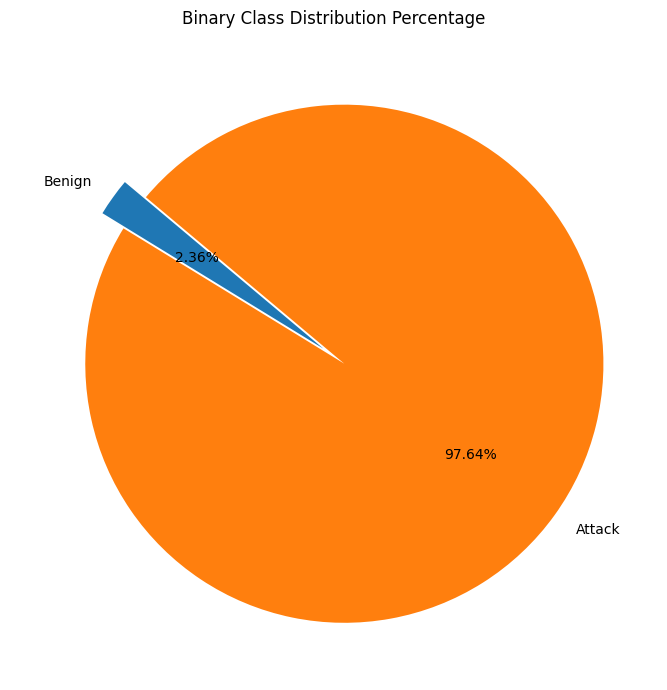

In [13]:
#-------------- Plot binary class distribution ---------------#

binary_counts = train_df["binary_label"].value_counts().sort_index()
binary_names = ["Benign" if i == 0 else "Attack" for i in binary_counts.index]

binary_dist_df = pd.DataFrame({
    "Class": binary_names,
    "Count": binary_counts.values,
    "Percentage": binary_counts.values / binary_counts.values.sum() * 100
})
binary_dist_df.to_csv(os.path.join(TABLE_DIR, "binary_train_class_distribution.csv"), index=False)

display(binary_dist_df)

plt.figure(figsize=(7, 5))
sns.barplot(data=binary_dist_df, x="Class", y="Count")
plt.title("Binary Class Distribution in CICIOT2023 Train Set")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
save_fig("binary_train_class_distribution_bar.png")

plt.figure(figsize=(7, 7))
plt.pie(binary_dist_df["Count"], labels=binary_dist_df["Class"], autopct="%1.2f%%", startangle=140, explode=[0.05] * len(binary_dist_df))
plt.title("Binary Class Distribution Percentage")
save_fig("binary_train_class_distribution_pie.png")


EDA sample shape: (100000, 48)


,count,mean,std,min,25%,50%,75%,max
flow_duration,100000.0,5.882019,281.930298,0.0,0.000000,0.000000,0.104350,5.347768e+04
Header_Length,100000.0,77103.148438,462114.093750,0.0,54.000000,54.000000,432.339989,9.716471e+06
Protocol Type,100000.0,9.058786,8.935328,0.0,6.000000,6.000000,14.300000,4.700000e+01
Duration,100000.0,66.397179,14.251970,0.0,64.000000,64.000000,64.000000,2.550000e+02
Rate,100000.0,9227.690430,98909.867188,0.0,2.095796,15.843466,118.845589,4.806672e+06
Srate,100000.0,9227.690430,98909.867188,0.0,2.095796,15.843466,118.845589,4.806672e+06
Drate,100000.0,0.000027,0.008473,0.0,0.000000,0.000000,0.000000,2.679210e+00
fin_flag_number,100000.0,0.086450,0.280933,0.0,0.000000,0.000000,0.000000,1.000000e+00
syn_flag_number,100000.0,0.206040,0.404311,0.0,0.000000,0.000000,0.000000,1.000000e+00
rst_flag_number,100000.0,0.090530,0.287059,0.0,0.000000,0.000000,0.000000,1.000000e+00


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/top_20_features_correlation_with_binary_label.png


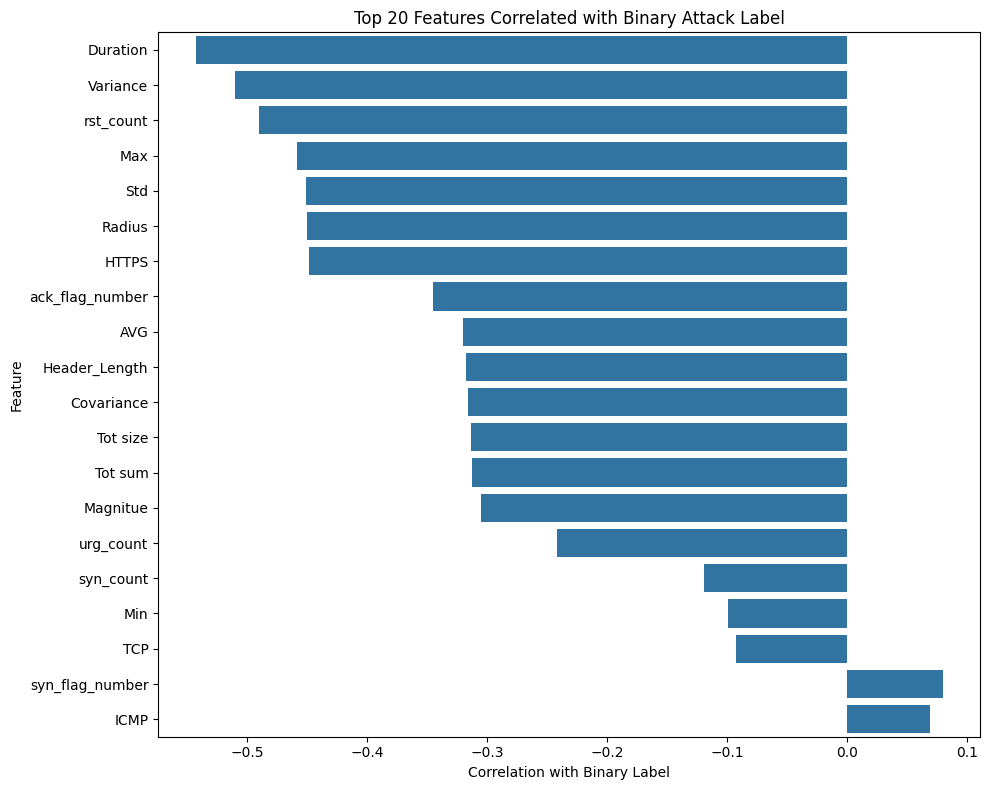

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/top_20_feature_correlation_heatmap.png


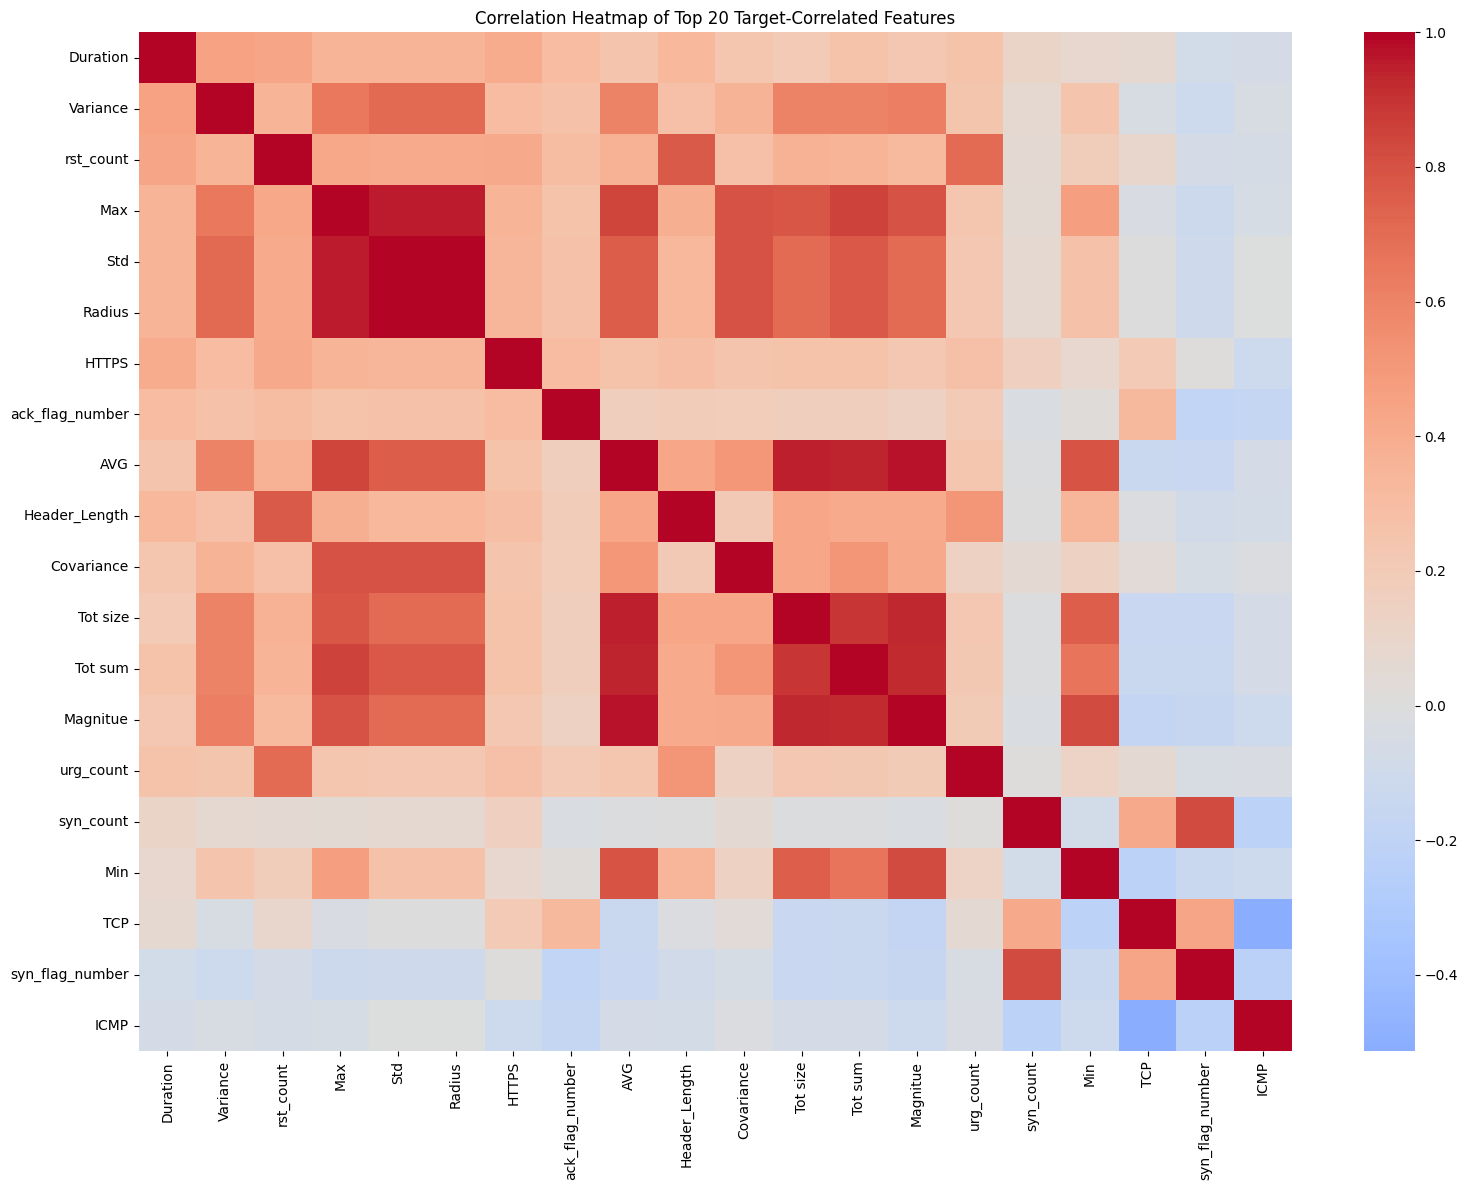

8522

In [14]:
#-------------- Feature summary and correlation analysis ---------------#

EDA_SAMPLE_SIZE = min(100_000, len(train_df))
eda_sample = train_df.sample(n=EDA_SAMPLE_SIZE, random_state=SEED).copy()

print("EDA sample shape:", eda_sample.shape)

feature_summary = eda_sample[FEATURE_COLUMNS].describe().T
feature_summary.to_csv(os.path.join(TABLE_DIR, "feature_summary_sample.csv"))
display(feature_summary.head(20))

# Correlation between features and binary label
corr_with_target = eda_sample[FEATURE_COLUMNS + ["binary_label"]].corr(numeric_only=True)["binary_label"].drop("binary_label").sort_values(key=lambda s: s.abs(), ascending=False)
corr_with_target.to_csv(os.path.join(TABLE_DIR, "feature_correlation_with_binary_label.csv"))

plt.figure(figsize=(10, 8))
sns.barplot(x=corr_with_target.head(20).values, y=corr_with_target.head(20).index)
plt.title("Top 20 Features Correlated with Binary Attack Label")
plt.xlabel("Correlation with Binary Label")
plt.ylabel("Feature")
save_fig("top_20_features_correlation_with_binary_label.png")

# Correlation heatmap for top correlated features
selected_corr_features = corr_with_target.head(20).index.tolist()
plt.figure(figsize=(16, 12))
sns.heatmap(eda_sample[selected_corr_features].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Top 20 Target-Correlated Features")
save_fig("top_20_feature_correlation_heatmap.png")

del eda_sample
gc.collect()


## 5. Feature Scaling and Sequence Dataset Preparation

Deep learning models use sequences of consecutive rows. The label of each sequence is the label of the final row in that sequence.

In [15]:
#-------------- Split into features and labels ---------------#

X_train = train_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32, copy=True)
y_train = train_df["binary_label"].to_numpy(dtype=np.int64, copy=True)

X_val = val_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32, copy=True)
y_val = val_df["binary_label"].to_numpy(dtype=np.int64, copy=True)

X_test = test_df[FEATURE_COLUMNS].to_numpy(dtype=np.float32, copy=True)
y_test = test_df["binary_label"].to_numpy(dtype=np.int64, copy=True)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

# Free dataframe memory after extraction
original_train_label_counts = train_df[LABEL_COLUMN].value_counts()
del train_df, val_df, test_df
gc.collect()


X_train: (5491971, 46) y_train: (5491971,)
X_val: (1176851, 46) y_val: (1176851,)
X_test: (1176851, 46) y_test: (1176851,)


16908

In [16]:
#-------------- Scale features using MinMaxScaler ---------------#

scaler = MinMaxScaler()

print("Fitting scaler on training data...")
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Scaled X_train range:", float(np.min(X_train_scaled)), "to", float(np.max(X_train_scaled)))
print("Scaled X_val range:", float(np.min(X_val_scaled)), "to", float(np.max(X_val_scaled)))
print("Scaled X_test range:", float(np.min(X_test_scaled)), "to", float(np.max(X_test_scaled)))

# Free unscaled feature arrays to reduce memory
# y arrays are kept for labels.
del X_train, X_val, X_test
gc.collect()


Fitting scaler on training data...
Scaled X_train range: 0.0 to 1.0000001192092896
Scaled X_val range: 0.0 to 10.471571922302246
Scaled X_test range: 0.0 to 1.0000001192092896


0

In [17]:
#-------------- Class weights for imbalanced binary classification ---------------#

class_counts = np.bincount(y_train, minlength=2)
total_count = class_counts.sum()
class_weights = total_count / (2 * np.maximum(class_counts, 1))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("Class counts [Benign, Attack]:", class_counts)
print("Class weights [Benign, Attack]:", class_weights)


Class counts [Benign, Attack]: [ 129538 5362433]
Class weights [Benign, Attack]: [21.19830088  0.51207829]


In [18]:
#-------------- Define PyTorch Dataset for on-the-fly sequence generation ---------------#

class StreamingSequenceDataset(Dataset):
    def __init__(self, X, y, seq_len=100):
        self.X = X.astype(np.float32, copy=False)
        self.y = y.astype(np.int64, copy=False)
        self.seq_len = seq_len

    def __len__(self):
        return max(len(self.X) - self.seq_len + 1, 0)

    def __getitem__(self, idx):
        x_seq = self.X[idx:idx + self.seq_len]
        y_label = self.y[idx + self.seq_len - 1]
        return torch.from_numpy(x_seq), torch.tensor(y_label, dtype=torch.long)

train_dataset = StreamingSequenceDataset(X_train_scaled, y_train, seq_len=SEQ_LEN)
val_dataset = StreamingSequenceDataset(X_val_scaled, y_val, seq_len=SEQ_LEN)
test_dataset = StreamingSequenceDataset(X_test_scaled, y_test, seq_len=SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print("Train sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))
print("Test sequences:", len(test_dataset))
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

sample_x, sample_y = next(iter(train_loader))
print("One batch input shape:", sample_x.shape)
print("One batch label shape:", sample_y.shape)


Train sequences: 5491872
Validation sequences: 1176752
Test sequences: 1176752
Train batches: 10727
Validation batches: 2299
Test batches: 2299
One batch input shape: torch.Size([512, 100, 46])
One batch label shape: torch.Size([512])


## 6. Deep Learning Model Architectures

Three deep learning architectures are trained:

-- CNN-only model  
-- LSTM-only model  
-- CNN-LSTM hybrid model with Bayesian optimization

This helps justify why the hybrid model is useful by comparing it against its individual CNN and LSTM components.

In [19]:
#-------------- CNN-only, LSTM-only, and CNN-LSTM architectures ---------------#

class CNNOnlyClassifier(nn.Module):
    def __init__(self, num_features, num_cnn_filters=64, dropout_rate=0.3, num_classes=2):
        super(CNNOnlyClassifier, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=num_features, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Conv1d(in_channels=num_cnn_filters, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Linear(num_cnn_filters, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x).squeeze(-1)
        return self.classifier(x)


class LSTMOnlyClassifier(nn.Module):
    def __init__(self, num_features, lstm_hidden_size=100, lstm_layers=2, dropout_rate=0.3, num_classes=2):
        super(LSTMOnlyClassifier, self).__init__()
        lstm_dropout = dropout_rate if lstm_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=num_features,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=lstm_dropout
        )
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        x = lstm_out[:, -1, :]
        return self.classifier(x)


class CNNLSTMClassifier(nn.Module):
    def __init__(self, num_features, num_cnn_filters=64, lstm_hidden_size=100, lstm_layers=2, dropout_rate=0.3, num_classes=2):
        super(CNNLSTMClassifier, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=num_features, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Conv1d(in_channels=num_cnn_filters, out_channels=num_cnn_filters, kernel_size=3, padding=1),
            nn.BatchNorm1d(num_cnn_filters),
            nn.ReLU()
        )
        lstm_dropout = dropout_rate if lstm_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=num_cnn_filters,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=lstm_dropout
        )
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        lstm_out, _ = self.lstm(x)
        x = lstm_out[:, -1, :]
        return self.classifier(x)


## 7. Training and Evaluation Utilities

In [20]:
#-------------- Device and common utilities ---------------#

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights_tensor = class_weights_tensor.to(device)

print("Device:", device)
print("Class weights tensor:", class_weights_tensor)


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_one_epoch(model, loader, criterion, optimizer, max_batches=None):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    loop = tqdm(loader, leave=False)
    for batch_idx, (batch_x, batch_y) in enumerate(loop):
        if max_batches is not None and batch_idx >= max_batches:
            break

        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_x.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)
        loop.set_description(f"loss={loss.item():.4f}")

    return running_loss / max(total, 1), correct / max(total, 1)


def validate_one_epoch(model, loader, criterion, max_batches=None):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for batch_idx, (batch_x, batch_y) in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break

            batch_x = batch_x.to(device, non_blocking=True)
            batch_y = batch_y.to(device, non_blocking=True)

            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            running_loss += loss.item() * batch_x.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

    return running_loss / max(total, 1), correct / max(total, 1)


def train_deep_model(model, model_name, train_loader, val_loader, epochs, learning_rate=0.001, max_train_batches=None, max_val_batches=None):
    print("=" * 100)
    print("Training:", model_name)
    print("Trainable parameters:", count_trainable_parameters(model))
    print("Learning rate:", learning_rate)
    print("Epochs:", epochs)

    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, max_batches=max_train_batches)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, max_batches=max_val_batches)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch:02d}/{epochs} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    training_time = time.time() - start_time
    print(f"{model_name} training time: {training_time:.2f} seconds")

    return history, training_time


Device: cuda
Class weights tensor: tensor([21.1983,  0.5121], device='cuda:0')


In [21]:
#-------------- Evaluation and plotting utilities ---------------#

def get_predictions_deep(model, loader, max_batches=None):
    model.eval()
    all_true, all_pred, all_prob = [], [], []
    start_time = time.time()

    with torch.no_grad():
        for batch_idx, (batch_x, batch_y) in enumerate(loader):
            if max_batches is not None and batch_idx >= max_batches:
                break

            batch_x = batch_x.to(device, non_blocking=True)
            outputs = model(batch_x)
            probs = torch.softmax(outputs, dim=1)[:, 1].detach().cpu().numpy()
            preds = torch.argmax(outputs, dim=1).detach().cpu().numpy()

            all_true.extend(batch_y.numpy())
            all_pred.extend(preds)
            all_prob.extend(probs)

    inference_time = time.time() - start_time
    return np.array(all_true), np.array(all_pred), np.array(all_prob), inference_time


def compute_metrics(y_true, y_pred, y_prob=None, model_name="Model", training_time=None, inference_time=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    specificity = tn / max(tn + fp, 1)
    far = fp / max(fp + tn, 1)
    fnr = fn / max(fn + tp, 1)

    if y_prob is not None and len(np.unique(y_true)) == 2:
        try:
            roc_auc = roc_auc_score(y_true, y_prob)
        except Exception:
            roc_auc = np.nan
        try:
            pr_auc = average_precision_score(y_true, y_prob)
        except Exception:
            pr_auc = np.nan
    else:
        roc_auc = np.nan
        pr_auc = np.nan

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "Specificity": specificity,
        "FAR": far,
        "FNR": fnr,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    }


def print_classification_outputs(model_name, y_true, y_pred):
    print("=" * 100)
    print(model_name)
    print("Confusion matrix [Benign, Attack]:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=["Benign", "Attack"], zero_division=0))


def plot_confusion_matrix_for_model(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Benign", "Attack"], yticklabels=["Benign", "Attack"])
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    save_fig(f"confusion_matrix_{model_name.replace(' ', '_').replace('-', '_')}.png")


def plot_training_history(history, model_name):
    history_df = pd.DataFrame(history)
    history_df.to_csv(os.path.join(TABLE_DIR, f"training_history_{model_name.replace(' ', '_').replace('-', '_')}.csv"), index=False)

    plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train Loss")
    plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")
    plt.title(f"Loss Curve - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    save_fig(f"loss_curve_{model_name.replace(' ', '_').replace('-', '_')}.png")

    plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["train_acc"], marker="o", label="Train Accuracy")
    plt.plot(history_df["epoch"], history_df["val_acc"], marker="o", label="Validation Accuracy")
    plt.title(f"Accuracy Curve - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    save_fig(f"accuracy_curve_{model_name.replace(' ', '_').replace('-', '_')}.png")


## 8. Train CNN-Only Model

Training: CNN Only
Trainable parameters: 25794
Learning rate: 0.001
Epochs: 8


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 01/8 | Train Loss: 0.1484 | Train Acc: 0.9458 | Val Loss: 0.0553 | Val Acc: 0.9762


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 02/8 | Train Loss: 0.0585 | Train Acc: 0.9773 | Val Loss: 0.0717 | Val Acc: 0.9651


...

Epoch 06/8 | Train Loss: 0.0458 | Train Acc: 0.9818 | Val Loss: 0.0441 | Val Acc: 0.9807


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 07/8 | Train Loss: 0.0456 | Train Acc: 0.9824 | Val Loss: 0.0390 | Val Acc: 0.9838


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 08/8 | Train Loss: 0.0433 | Train Acc: 0.9833 | Val Loss: 0.0385 | Val Acc: 0.9842
CNN Only training time: 262.89 seconds
Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/loss_curve_CNN_Only.png


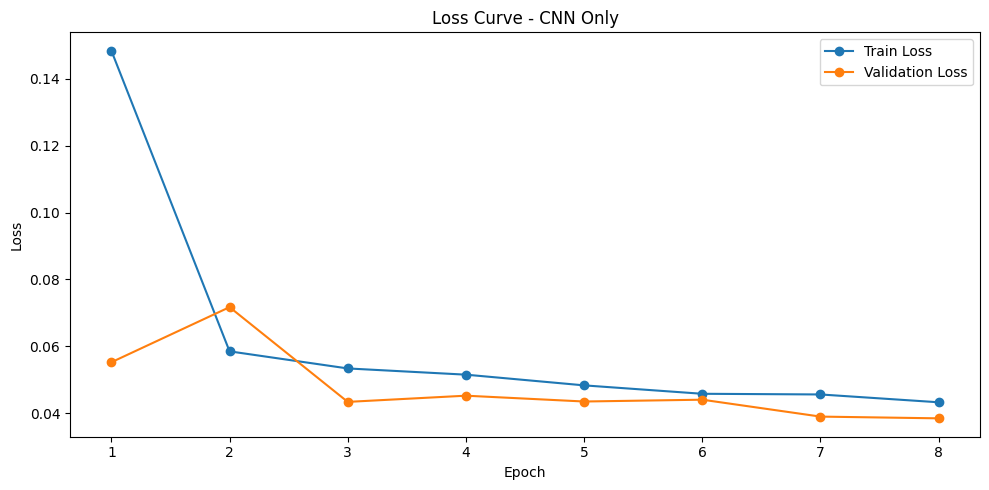

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/accuracy_curve_CNN_Only.png


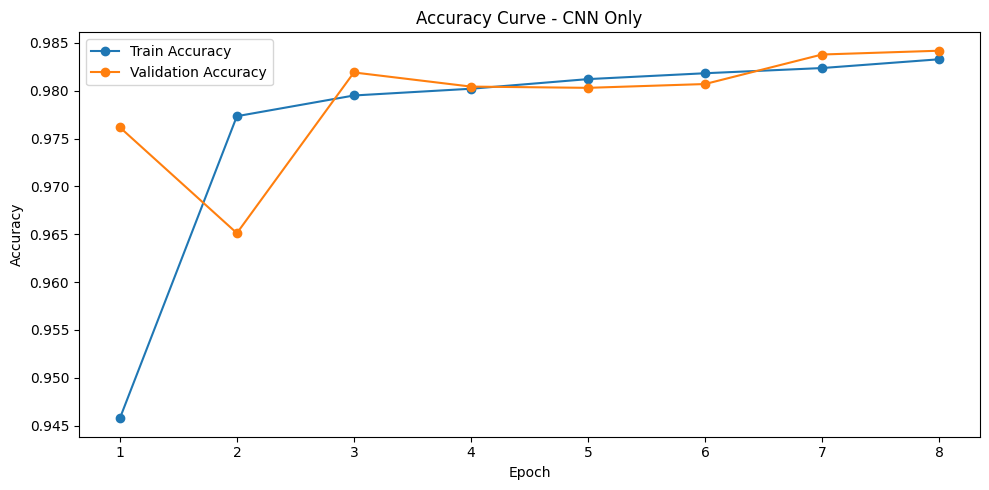

In [22]:
#-------------- Train CNN-only model ---------------#

cnn_model = CNNOnlyClassifier(num_features=NUM_FEATURES, num_cnn_filters=64, dropout_rate=0.3, num_classes=2).to(device)
cnn_history, cnn_training_time = train_deep_model(
    cnn_model,
    model_name="CNN Only",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=CNN_EPOCHS,
    learning_rate=0.001,
    max_train_batches=FINAL_MAX_TRAIN_BATCHES_PER_EPOCH,
    max_val_batches=FINAL_MAX_VAL_BATCHES_PER_EPOCH
)

plot_training_history(cnn_history, "CNN Only")


CNN Only
Confusion matrix [Benign, Attack]:
[[  5957      5]
 [  4067 245971]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.59      1.00      0.75      5962
      Attack       1.00      0.98      0.99    250038

    accuracy                           0.98    256000
   macro avg       0.80      0.99      0.87    256000
weighted avg       0.99      0.98      0.99    256000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_CNN_Only.png


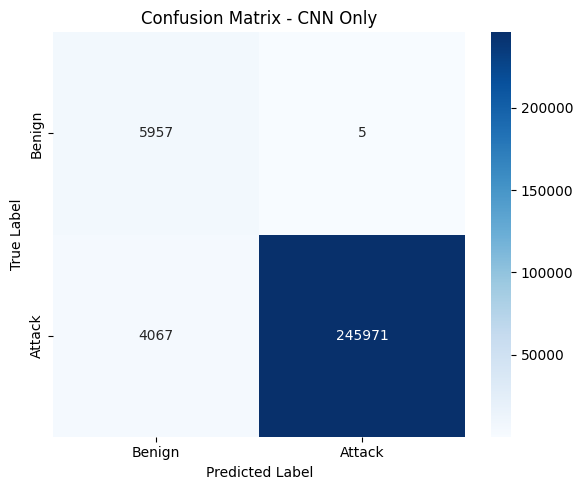

{'Model': 'CNN Only',
 'Accuracy': 0.98409375,
 'Precision': 0.9999796728136078,
 'Recall': 0.9837344723602013,
 'F1 Score': 0.9917905542988706,
 'Specificity': np.float64(0.9991613552499161),
 'FAR': np.float64(0.0008386447500838644),
 'FNR': np.float64(0.01626552763979875),
 'ROC-AUC': np.float64(0.9961596961045885),
 'PR-AUC': np.float64(0.9999091896030486),
 'TN': 5957,
 'FP': 5,
 'FN': 4067,
 'TP': 245971,
 'Training Time (s)': 262.8894443511963,
 'Inference Time (s)': 4.5767645835876465}

In [23]:
#-------------- Evaluate CNN-only model ---------------#

y_true_cnn, y_pred_cnn, y_prob_cnn, cnn_inference_time = get_predictions_deep(cnn_model, test_loader, max_batches=MAX_EVAL_BATCHES)
cnn_results = compute_metrics(y_true_cnn, y_pred_cnn, y_prob_cnn, "CNN Only", cnn_training_time, cnn_inference_time)
print_classification_outputs("CNN Only", y_true_cnn, y_pred_cnn)
plot_confusion_matrix_for_model(y_true_cnn, y_pred_cnn, "CNN Only")
cnn_results


## 9. Train LSTM-Only Model

Training: LSTM Only
Trainable parameters: 146594
Learning rate: 0.001
Epochs: 8


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 01/8 | Train Loss: 0.0978 | Train Acc: 0.9690 | Val Loss: 0.0563 | Val Acc: 0.9783


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 02/8 | Train Loss: 0.0610 | Train Acc: 0.9755 | Val Loss: 0.0528 | Val Acc: 0.9799


...

Epoch 06/8 | Train Loss: 0.0424 | Train Acc: 0.9833 | Val Loss: 0.0379 | Val Acc: 0.9835


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 07/8 | Train Loss: 0.0395 | Train Acc: 0.9843 | Val Loss: 0.0352 | Val Acc: 0.9849


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 08/8 | Train Loss: 0.0375 | Train Acc: 0.9851 | Val Loss: 0.0349 | Val Acc: 0.9855
LSTM Only training time: 472.76 seconds
Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/loss_curve_LSTM_Only.png


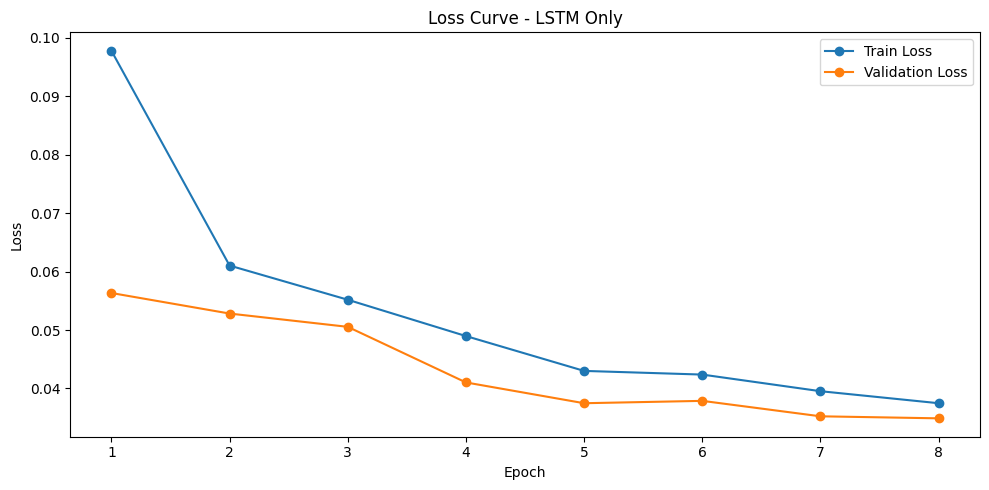

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/accuracy_curve_LSTM_Only.png


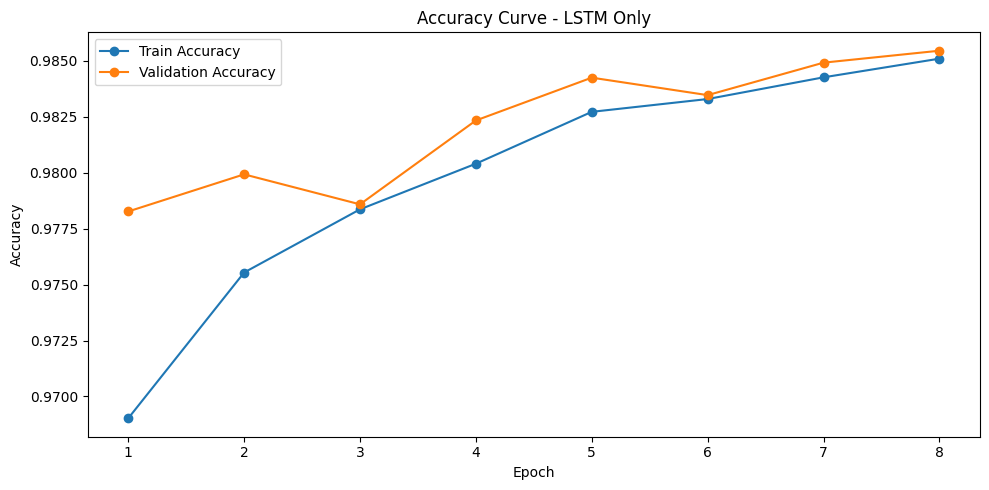

In [24]:
#-------------- Train LSTM-only model ---------------#

lstm_model = LSTMOnlyClassifier(num_features=NUM_FEATURES, lstm_hidden_size=100, lstm_layers=2, dropout_rate=0.3, num_classes=2).to(device)
lstm_history, lstm_training_time = train_deep_model(
    lstm_model,
    model_name="LSTM Only",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=LSTM_EPOCHS,
    learning_rate=0.001,
    max_train_batches=FINAL_MAX_TRAIN_BATCHES_PER_EPOCH,
    max_val_batches=FINAL_MAX_VAL_BATCHES_PER_EPOCH
)

plot_training_history(lstm_history, "LSTM Only")


LSTM Only
Confusion matrix [Benign, Attack]:
[[  5954      8]
 [  3776 246262]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.61      1.00      0.76      5962
      Attack       1.00      0.98      0.99    250038

    accuracy                           0.99    256000
   macro avg       0.81      0.99      0.88    256000
weighted avg       0.99      0.99      0.99    256000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_LSTM_Only.png


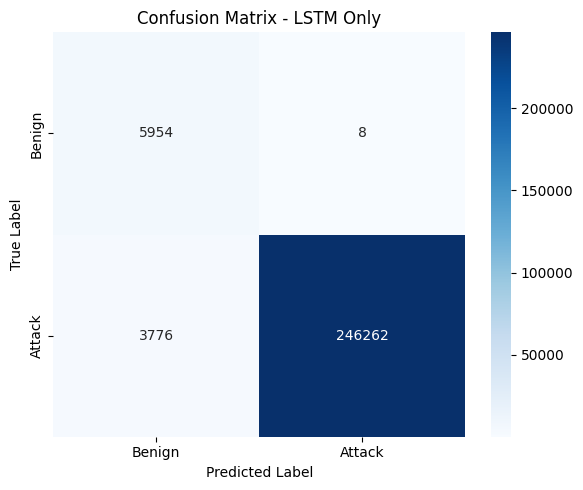

{'Model': 'LSTM Only',
 'Accuracy': 0.98521875,
 'Precision': 0.9999675153287043,
 'Recall': 0.9848982954590902,
 'F1 Score': 0.9923757021849335,
 'Specificity': np.float64(0.9986581683998658),
 'FAR': np.float64(0.0013418316001341832),
 'FNR': np.float64(0.015101704540909781),
 'ROC-AUC': np.float64(0.9968329812191259),
 'PR-AUC': np.float64(0.9999250683389412),
 'TN': 5954,
 'FP': 8,
 'FN': 3776,
 'TP': 246262,
 'Training Time (s)': 472.75939178466797,
 'Inference Time (s)': 8.560029983520508}

In [25]:
#-------------- Evaluate LSTM-only model ---------------#

y_true_lstm, y_pred_lstm, y_prob_lstm, lstm_inference_time = get_predictions_deep(lstm_model, test_loader, max_batches=MAX_EVAL_BATCHES)
lstm_results = compute_metrics(y_true_lstm, y_pred_lstm, y_prob_lstm, "LSTM Only", lstm_training_time, lstm_inference_time)
print_classification_outputs("LSTM Only", y_true_lstm, y_pred_lstm)
plot_confusion_matrix_for_model(y_true_lstm, y_pred_lstm, "LSTM Only")
lstm_results


## 10. Bayesian Optimization for CNN-LSTM

Optuna is used to tune the hybrid CNN-LSTM model. The visualizations are manually generated using Matplotlib so they appear in Kaggle output cells.

In [26]:
#-------------- Optuna objective function ---------------#

def objective(trial):
    num_cnn_filters = trial.suggest_categorical("num_cnn_filters", [32, 64, 128])
    lstm_hidden_size = trial.suggest_categorical("lstm_hidden_size", [64, 100, 128])
    lstm_layers = trial.suggest_int("lstm_layers", 1, 3)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 5e-3, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5)

    model = CNNLSTMClassifier(
        num_features=NUM_FEATURES,
        num_cnn_filters=num_cnn_filters,
        lstm_hidden_size=lstm_hidden_size,
        lstm_layers=lstm_layers,
        dropout_rate=dropout_rate,
        num_classes=2
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(OPTUNA_EPOCHS):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, max_batches=OPTUNA_MAX_TRAIN_BATCHES)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, max_batches=OPTUNA_MAX_VAL_BATCHES)
        trial.report(val_acc, epoch)

        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return val_acc


In [27]:
#-------------- Run Optuna Bayesian optimization ---------------#

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1)
)

study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)

print("Best trial validation accuracy:", study.best_trial.value)
print("Best hyperparameters:")
for k, v in study.best_trial.params.items():
    print(f"{k}: {v}")

trials_df = study.trials_dataframe()
trials_df.to_csv(os.path.join(TABLE_DIR, "optuna_trials.csv"), index=False)
display(trials_df)


[I 2026-06-03 17:01:22,088] A new study created in memory with name: no-name-01db43ab-6d17-4c7c-825e-51587c38f7ba


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10727 [00:00<?, ?it/s]

  0%|          | 0/10727 [00:00<?, ?it/s]

  0%|          | 0/10727 [00:00<?, ?it/s]

...

[I 2026-06-03 17:09:00,818] Trial 8 pruned. 


  0%|          | 0/10727 [00:00<?, ?it/s]

  0%|          | 0/10727 [00:00<?, ?it/s]

[I 2026-06-03 17:09:39,295] Trial 9 pruned. 
Best trial validation accuracy: 0.9837369791666667
Best hyperparameters:
num_cnn_filters: 128
lstm_hidden_size: 100
lstm_layers: 3
learning_rate: 0.0020512599422151364
dropout_rate: 0.17948627261366898


,number,value,datetime_start,datetime_complete,duration,params_dropout_rate,params_learning_rate,params_lstm_hidden_size,params_lstm_layers,params_num_cnn_filters,state
0,0,0.980664,2026-06-03 17:01:22.097705,2026-06-03 17:01:52.581148,0 days 00:00:30.483443,0.340446,0.002962,64,1,64,COMPLETE
1,1,0.981784,2026-06-03 17:01:52.583501,2026-06-03 17:02:37.175767,0 days 00:00:44.592266,0.309903,0.000329,64,1,128,COMPLETE
2,2,0.980755,2026-06-03 17:02:37.178237,2026-06-03 17:03:54.859163,0 days 00:01:17.680926,0.179870,0.002158,128,2,128,COMPLETE
3,3,0.966341,2026-06-03 17:03:54.861406,2026-06-03 17:04:20.487229,0 days 00:00:25.625823,0.423359,0.004371,64,3,64,PRUNED
4,4,0.983008,2026-06-03 17:04:20.489386,2026-06-03 17:05:17.023128,0 days 00:00:56.533742,0.203512,0.003507,128,1,128,COMPLETE
5,5,0.978802,2026-06-03 17:05:17.025782,2026-06-03 17:06:10.705755,0 days 00:00:53.679973,0.457931,0.003946,128,3,32,PRUNED
6,6,0.974180,2026-06-03 17:06:10.708121,2026-06-03 17:06:52.630600,0 days 00:00:41.922479,0.431495,0.000289,128,2,64,PRUNED
7,7,0.983737,2026-06-03 17:06:52.633071,2026-06-03 17:08:22.890321,0 days 00:01:30.257250,0.179486,0.002051,100,3,128,COMPLETE
8,8,0.968294,2026-06-03 17:08:22.893411,2026-06-03 17:09:00.818516,0 days 00:00:37.925105,0.445241,0.000157,100,2,64,PRUNED
9,9,0.978398,2026-06-03 17:09:00.820771,2026-06-03 17:09:39.295606,0 days 00:00:38.474835,0.288886,0.003216,128,2,32,PRUNED


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_optimization_history.png


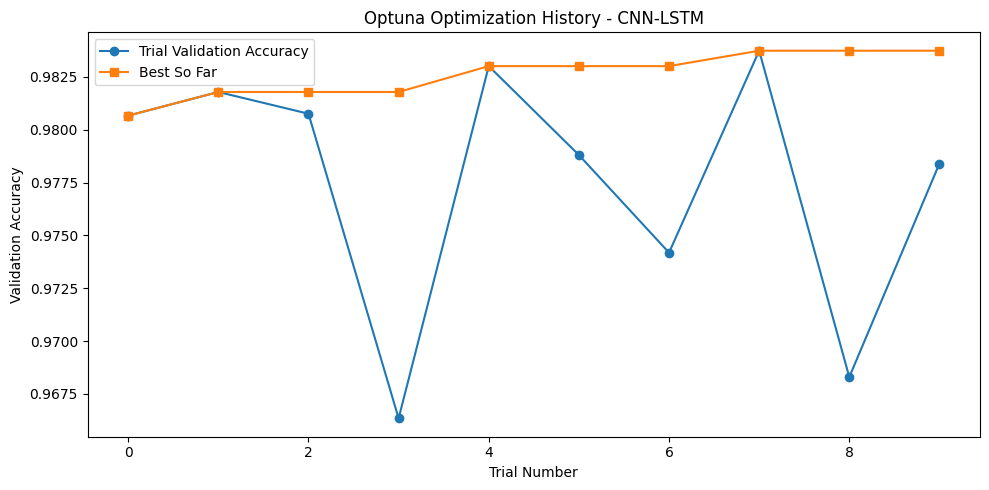

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_hyperparameter_importance.png


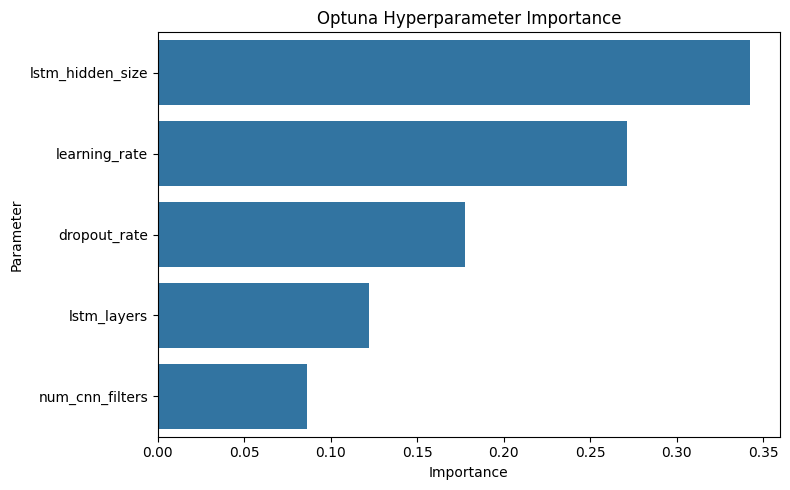

,Parameter,Importance
0,lstm_hidden_size,0.342616
1,learning_rate,0.271398
2,dropout_rate,0.177523
3,lstm_layers,0.122343
4,num_cnn_filters,0.086120


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_slice_num_cnn_filters.png


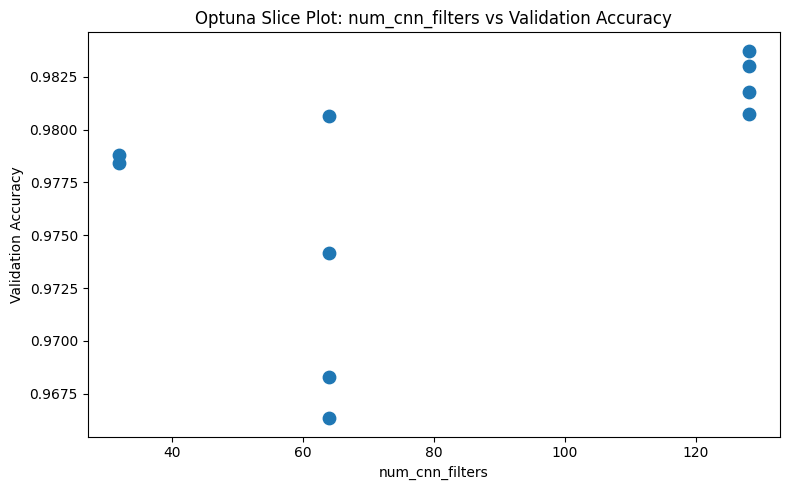

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_slice_lstm_hidden_size.png


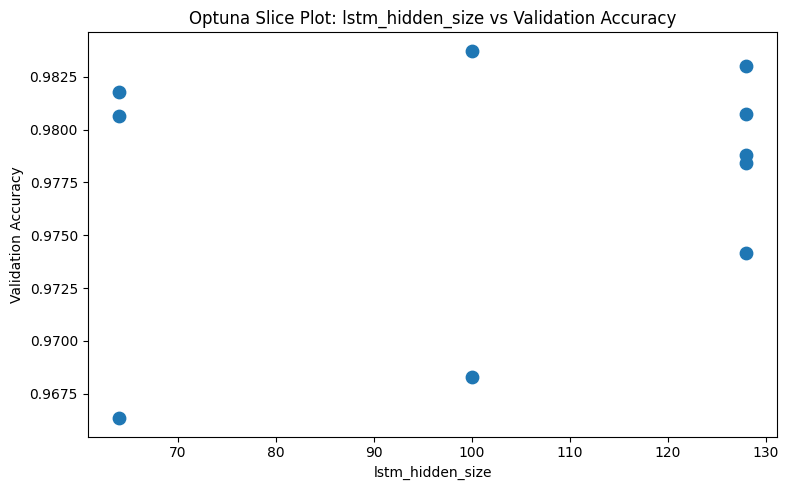

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_slice_lstm_layers.png


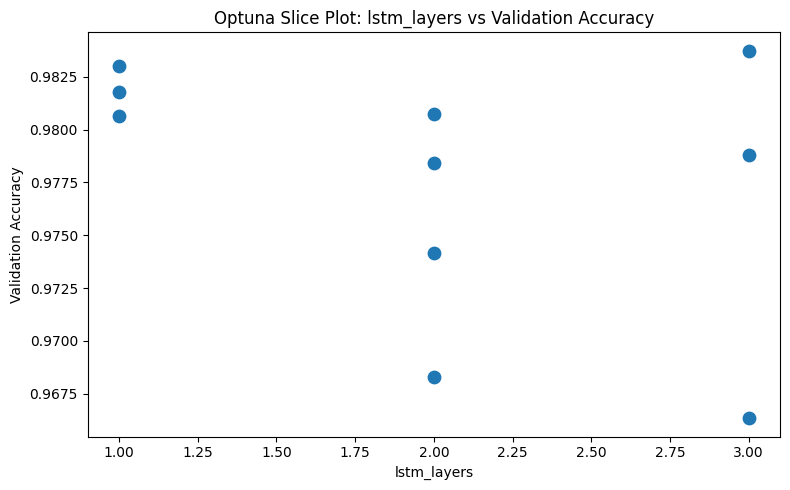

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_slice_learning_rate.png


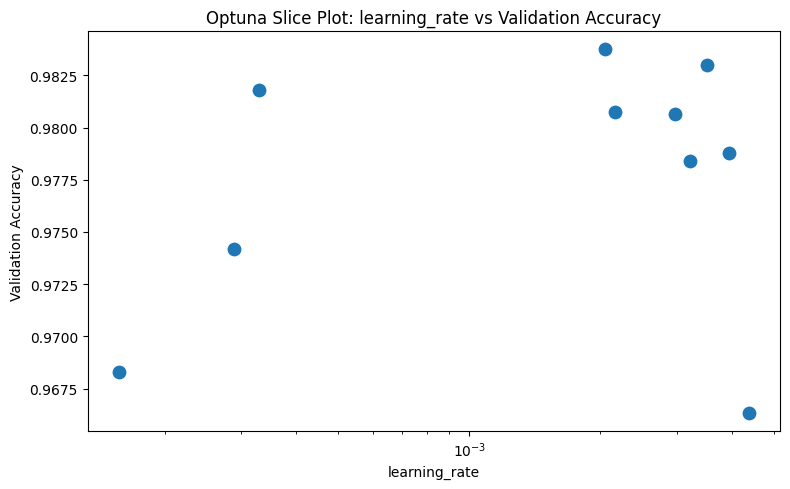

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_slice_dropout_rate.png


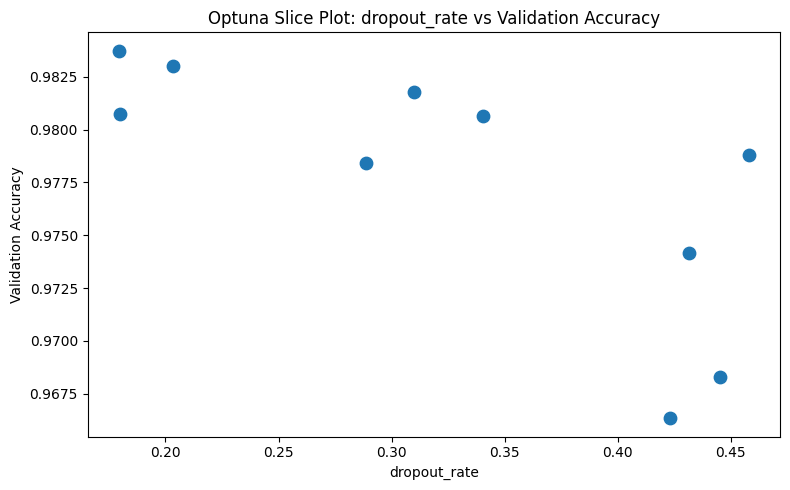

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/optuna_learning_rate_vs_dropout.png


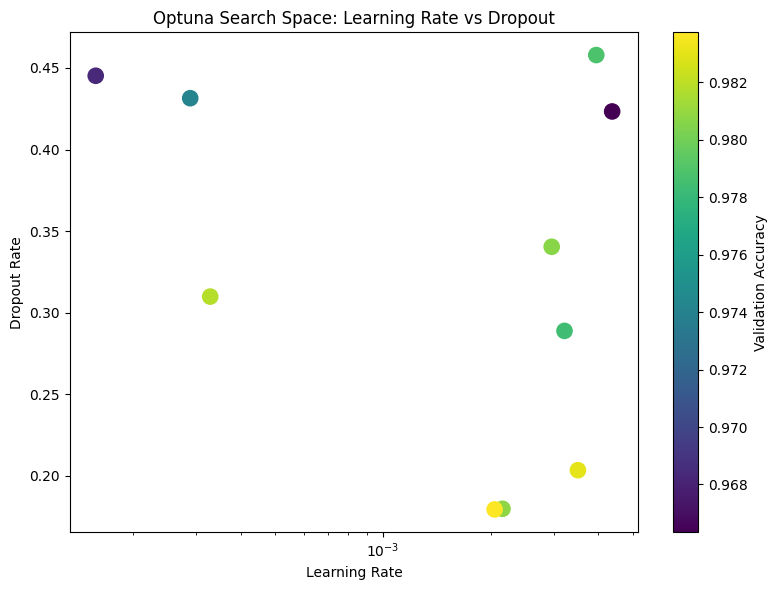

In [28]:
#-------------- Matplotlib Optuna visualizations for Kaggle ---------------#

completed_trials = [t for t in study.trials if t.value is not None]
trial_numbers = [t.number for t in completed_trials]
trial_values = [t.value for t in completed_trials]

# 1. Optimization history
plt.figure(figsize=(10, 5))
plt.plot(trial_numbers, trial_values, marker="o", label="Trial Validation Accuracy")
if len(trial_values) > 0:
    best_so_far = np.maximum.accumulate(trial_values)
    plt.plot(trial_numbers, best_so_far, marker="s", label="Best So Far")
plt.title("Optuna Optimization History - CNN-LSTM")
plt.xlabel("Trial Number")
plt.ylabel("Validation Accuracy")
plt.legend()
save_fig("optuna_optimization_history.png")

# 2. Parameter importance
try:
    importances = get_param_importances(study)
    importance_df = pd.DataFrame({"Parameter": list(importances.keys()), "Importance": list(importances.values())})
    importance_df.to_csv(os.path.join(TABLE_DIR, "optuna_param_importance.csv"), index=False)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=importance_df, x="Importance", y="Parameter")
    plt.title("Optuna Hyperparameter Importance")
    save_fig("optuna_hyperparameter_importance.png")
    display(importance_df)
except Exception as e:
    print("Could not compute parameter importance:", e)

# 3. Slice plots for all parameters
param_names = ["num_cnn_filters", "lstm_hidden_size", "lstm_layers", "learning_rate", "dropout_rate"]
for param in param_names:
    xs, ys = [], []
    for t in completed_trials:
        if param in t.params and t.value is not None:
            xs.append(t.params[param])
            ys.append(t.value)

    if len(xs) > 0:
        plt.figure(figsize=(8, 5))
        plt.scatter(xs, ys, s=80)
        plt.title(f"Optuna Slice Plot: {param} vs Validation Accuracy")
        plt.xlabel(param)
        plt.ylabel("Validation Accuracy")
        if param == "learning_rate":
            plt.xscale("log")
        save_fig(f"optuna_slice_{param}.png")

# 4. Learning rate vs dropout scatter
lr_values, dropout_values, acc_values = [], [], []
for t in completed_trials:
    if "learning_rate" in t.params and "dropout_rate" in t.params and t.value is not None:
        lr_values.append(t.params["learning_rate"])
        dropout_values.append(t.params["dropout_rate"])
        acc_values.append(t.value)

if len(lr_values) > 0:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(lr_values, dropout_values, c=acc_values, s=120, cmap="viridis")
    plt.xscale("log")
    plt.colorbar(scatter, label="Validation Accuracy")
    plt.title("Optuna Search Space: Learning Rate vs Dropout")
    plt.xlabel("Learning Rate")
    plt.ylabel("Dropout Rate")
    save_fig("optuna_learning_rate_vs_dropout.png")


## 11. Train Final Bayesian-Optimized CNN-LSTM Model

CNNLSTMClassifier(
  (cnn): Sequential(
    (0): Conv1d(46, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.17948627261366898, inplace=False)
    (4): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
  )
  (lstm): LSTM(128, 100, num_layers=3, batch_first=True, dropout=0.17948627261366898)
  (classifier): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.17948627261366898, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 327778
Training: Bayesian CNN-LSTM
Trainable parameters: 327778
Learning rate: 0.0020512599422151364
Epochs: 15


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 01/15 | Train Loss: 0.0648 | Train Acc: 0.9723 | Val Loss: 0.0442 | Val Acc: 0.9822


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 02/15 | Train Loss: 0.0472 | Train Acc: 0.9821 | Val Loss: 0.0422 | Val Acc: 0.9838


...

Epoch 13/15 | Train Loss: 0.0390 | Train Acc: 0.9846 | Val Loss: 0.0364 | Val Acc: 0.9850


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 14/15 | Train Loss: 0.0391 | Train Acc: 0.9846 | Val Loss: 0.0336 | Val Acc: 0.9858


  0%|          | 0/10727 [00:00<?, ?it/s]

Epoch 15/15 | Train Loss: 0.0366 | Train Acc: 0.9858 | Val Loss: 0.0367 | Val Acc: 0.9851
Bayesian CNN-LSTM training time: 1642.82 seconds
Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/loss_curve_Bayesian_CNN_LSTM.png


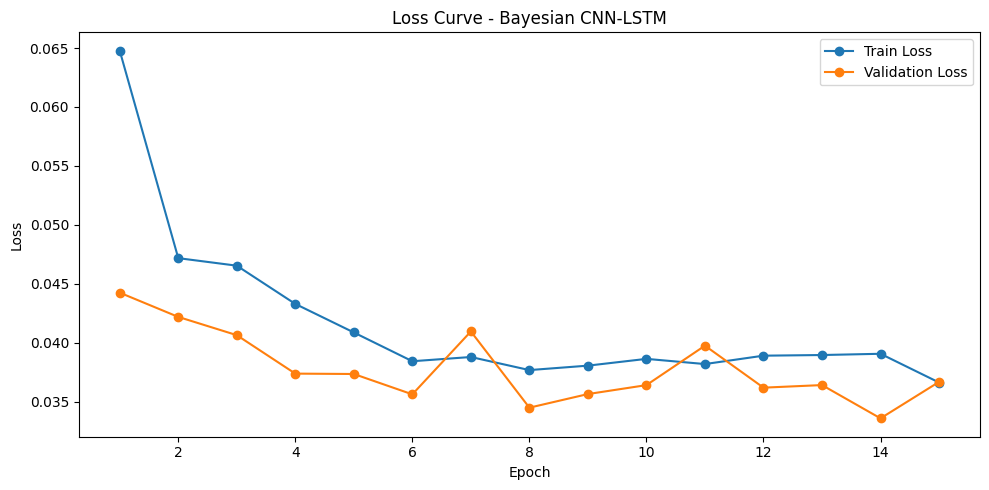

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/accuracy_curve_Bayesian_CNN_LSTM.png


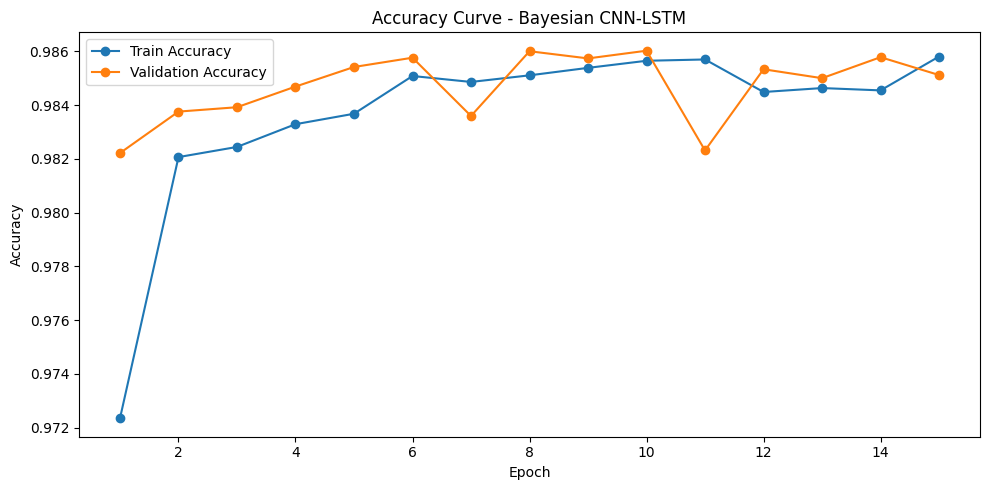

In [29]:
#-------------- Train final CNN-LSTM with best hyperparameters ---------------#

best_params = study.best_trial.params

cnn_lstm_model = CNNLSTMClassifier(
    num_features=NUM_FEATURES,
    num_cnn_filters=best_params["num_cnn_filters"],
    lstm_hidden_size=best_params["lstm_hidden_size"],
    lstm_layers=best_params["lstm_layers"],
    dropout_rate=best_params["dropout_rate"],
    num_classes=2
).to(device)

print(cnn_lstm_model)
print("Trainable parameters:", count_trainable_parameters(cnn_lstm_model))

cnn_lstm_history, cnn_lstm_training_time = train_deep_model(
    cnn_lstm_model,
    model_name="Bayesian CNN-LSTM",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=FINAL_CNN_LSTM_EPOCHS,
    learning_rate=best_params["learning_rate"],
    max_train_batches=FINAL_MAX_TRAIN_BATCHES_PER_EPOCH,
    max_val_batches=FINAL_MAX_VAL_BATCHES_PER_EPOCH
)

plot_training_history(cnn_lstm_history, "Bayesian CNN-LSTM")


Bayesian CNN-LSTM
Confusion matrix [Benign, Attack]:
[[  5961      1]
 [  3820 246218]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.61      1.00      0.76      5962
      Attack       1.00      0.98      0.99    250038

    accuracy                           0.99    256000
   macro avg       0.80      0.99      0.87    256000
weighted avg       0.99      0.99      0.99    256000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Bayesian_CNN_LSTM.png


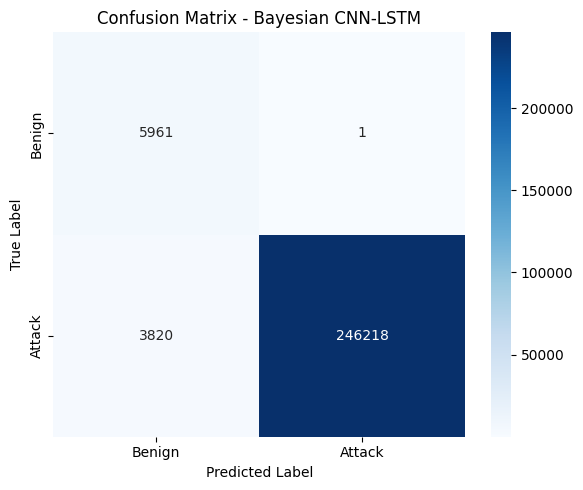

{'Model': 'Bayesian CNN-LSTM',
 'Accuracy': 0.98507421875,
 'Precision': 0.9999959385750085,
 'Recall': 0.9847223222070245,
 'F1 Score': 0.9923003604986932,
 'Specificity': np.float64(0.9998322710499832),
 'FAR': np.float64(0.0001677289500167729),
 'FNR': np.float64(0.015277677792975468),
 'ROC-AUC': np.float64(0.9962775517229063),
 'PR-AUC': np.float64(0.9999119368038163),
 'TN': 5961,
 'FP': 1,
 'FN': 3820,
 'TP': 246218,
 'Training Time (s)': 1642.8197433948517,
 'Inference Time (s)': 15.020688772201538}

In [30]:
#-------------- Evaluate Bayesian CNN-LSTM ---------------#

y_true_cnn_lstm, y_pred_cnn_lstm, y_prob_cnn_lstm, cnn_lstm_inference_time = get_predictions_deep(cnn_lstm_model, test_loader, max_batches=MAX_EVAL_BATCHES)
cnn_lstm_results = compute_metrics(y_true_cnn_lstm, y_pred_cnn_lstm, y_prob_cnn_lstm, "Bayesian CNN-LSTM", cnn_lstm_training_time, cnn_lstm_inference_time)
print_classification_outputs("Bayesian CNN-LSTM", y_true_cnn_lstm, y_pred_cnn_lstm)
plot_confusion_matrix_for_model(y_true_cnn_lstm, y_pred_cnn_lstm, "Bayesian CNN-LSTM")
cnn_lstm_results


## 12. Five Classical Machine Learning Baseline Models

The five classical ML models are trained without Bayesian optimization:

-- Logistic Regression  
-- Gaussian Naive Bayes  
-- Decision Tree  
-- Random Forest  
-- Histogram Gradient Boosting

In [31]:
#-------------- Stratified sampling for classical ML models ---------------#

def stratified_sample_arrays(X, y, max_samples, seed=42):
    if max_samples is None or len(y) <= max_samples:
        return X, y

    splitter = StratifiedShuffleSplit(n_splits=1, train_size=max_samples, random_state=seed)
    sample_idx, _ = next(splitter.split(X, y))
    return X[sample_idx], y[sample_idx]

X_ml_train, y_ml_train = stratified_sample_arrays(X_train_scaled, y_train, ML_TRAIN_SAMPLE_SIZE, seed=SEED)
X_ml_test, y_ml_test = stratified_sample_arrays(X_test_scaled, y_test, ML_TEST_SAMPLE_SIZE, seed=SEED)

print("ML train shape:", X_ml_train.shape, y_ml_train.shape)
print("ML test shape:", X_ml_test.shape, y_ml_test.shape)
print("ML train distribution:", np.bincount(y_ml_train, minlength=2))
print("ML test distribution:", np.bincount(y_ml_test, minlength=2))


ML train shape: (500000, 46) (500000,)
ML test shape: (300000, 46) (300000,)
ML train distribution: [ 11793 488207]
ML test distribution: [  7064 292936]


Training ML model: Logistic Regression
Logistic Regression
Confusion matrix [Benign, Attack]:
[[  7041     23]
 [  7443 285493]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.49      1.00      0.65      7064
      Attack       1.00      0.97      0.99    292936

    accuracy                           0.98    300000
   macro avg       0.74      0.99      0.82    300000
weighted avg       0.99      0.98      0.98    300000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Logistic_Regression.png


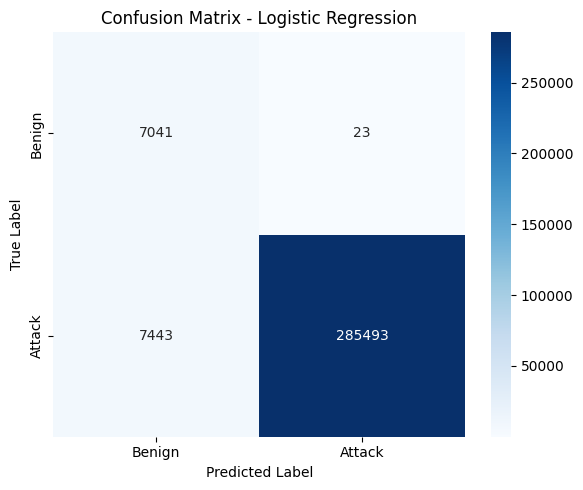

Training ML model: Gaussian Naive Bayes
Gaussian Naive Bayes
Confusion matrix [Benign, Attack]:
[[  7054     10]
 [ 67879 225057]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.09      1.00      0.17      7064
      Attack       1.00      0.77      0.87    292936

    accuracy                           0.77    300000
   macro avg       0.55      0.88      0.52    300000
weighted avg       0.98      0.77      0.85    300000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Gaussian_Naive_Bayes.png


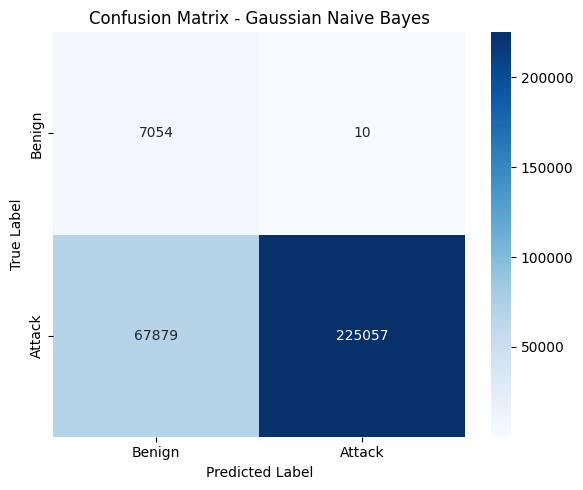

Training ML model: Decision Tree
Decision Tree
Confusion matrix [Benign, Attack]:
[[  6365    699]
 [   580 292356]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.92      0.90      0.91      7064
      Attack       1.00      1.00      1.00    292936

    accuracy                           1.00    300000
   macro avg       0.96      0.95      0.95    300000
weighted avg       1.00      1.00      1.00    300000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Decision_Tree.png


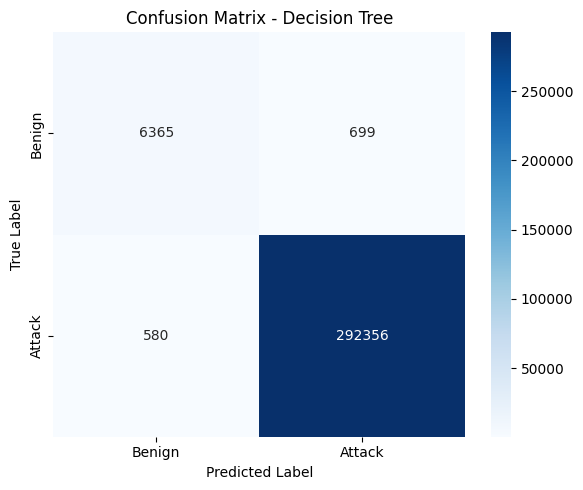

Training ML model: Random Forest
Random Forest
Confusion matrix [Benign, Attack]:
[[  6633    431]
 [   496 292440]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.93      0.94      0.93      7064
      Attack       1.00      1.00      1.00    292936

    accuracy                           1.00    300000
   macro avg       0.96      0.97      0.97    300000
weighted avg       1.00      1.00      1.00    300000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Random_Forest.png


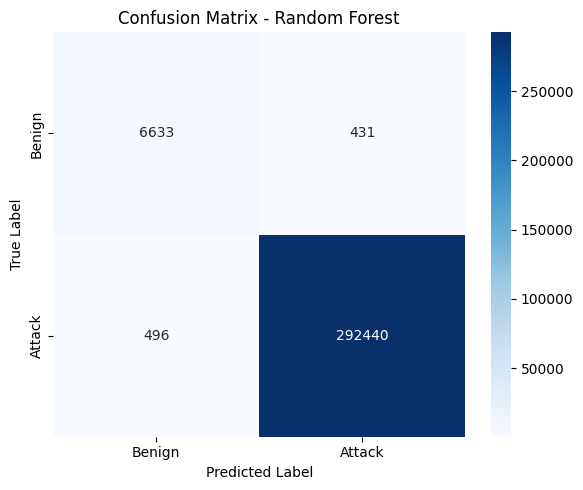

Training ML model: Hist Gradient Boosting
Hist Gradient Boosting
Confusion matrix [Benign, Attack]:
[[  6637    427]
 [   779 292157]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.89      0.94      0.92      7064
      Attack       1.00      1.00      1.00    292936

    accuracy                           1.00    300000
   macro avg       0.95      0.97      0.96    300000
weighted avg       1.00      1.00      1.00    300000

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/confusion_matrix_Hist_Gradient_Boosting.png


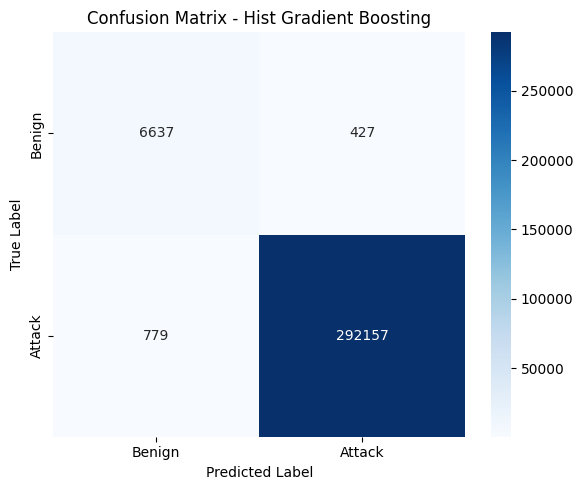

,Model,Accuracy,Precision,Recall,F1 Score,Specificity,FAR,FNR,ROC-AUC,PR-AUC,TN,FP,FN,TP,Training Time (s),Inference Time (s)
0,Logistic Regression,0.975113,0.999919,0.974592,0.987093,0.996744,0.003256,0.025408,0.993794,0.999851,7041,23,7443,285493,7.297142,0.027905
1,Gaussian Naive Bayes,0.773703,0.999956,0.768280,0.868941,0.998584,0.001416,0.231720,0.992178,0.999794,7054,10,67879,225057,0.207270,0.168317
2,Decision Tree,0.995737,0.997615,0.998020,0.997817,0.901048,0.098952,0.001980,0.949534,0.997573,6365,699,580,292356,4.602397,0.016037
3,Random Forest,0.996910,0.998528,0.998307,0.998418,0.938986,0.061014,0.001693,0.999593,0.999990,6633,431,496,292440,25.650570,0.390614
4,Hist Gradient Boosting,0.995980,0.998541,0.997341,0.997940,0.939553,0.060447,0.002659,0.999352,0.999984,6637,427,779,292157,6.469641,1.966381


In [32]:
#-------------- Train and evaluate classical ML models ---------------#

ml_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED)
}

ml_results = []
ml_predictions = {}

for name, clf in ml_models.items():
    print("=" * 100)
    print("Training ML model:", name)
    start_train = time.time()
    clf.fit(X_ml_train, y_ml_train)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = clf.predict(X_ml_test)
    inference_time = time.time() - start_pred

    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_ml_test)[:, 1]
    elif hasattr(clf, "decision_function"):
        scores = clf.decision_function(X_ml_test)
        y_prob = (scores - scores.min()) / max(scores.max() - scores.min(), 1e-9)
    else:
        y_prob = None

    result = compute_metrics(y_ml_test, y_pred, y_prob, name, train_time, inference_time)
    ml_results.append(result)
    ml_predictions[name] = {"y_true": y_ml_test, "y_pred": y_pred, "y_prob": y_prob}

    print_classification_outputs(name, y_ml_test, y_pred)
    plot_confusion_matrix_for_model(y_ml_test, y_pred, name)

    joblib.dump(clf, os.path.join(MODEL_DIR, f"{name.replace(' ', '_').replace('-', '_')}.joblib"))

ml_results_df = pd.DataFrame(ml_results)
display(ml_results_df)
ml_results_df.to_csv(os.path.join(TABLE_DIR, "classical_ml_results.csv"), index=False)


,Feature,Importance
18,rst_count,0.927931
39,IAT,0.025720
0,flow_duration,0.014828
41,Magnitue,0.004242
1,Header_Length,0.004151
44,Variance,0.004089
40,Number,0.003247
2,Protocol Type,0.001892
19,HTTP,0.001739
17,urg_count,0.001610


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/feature_importance_Decision_Tree.png


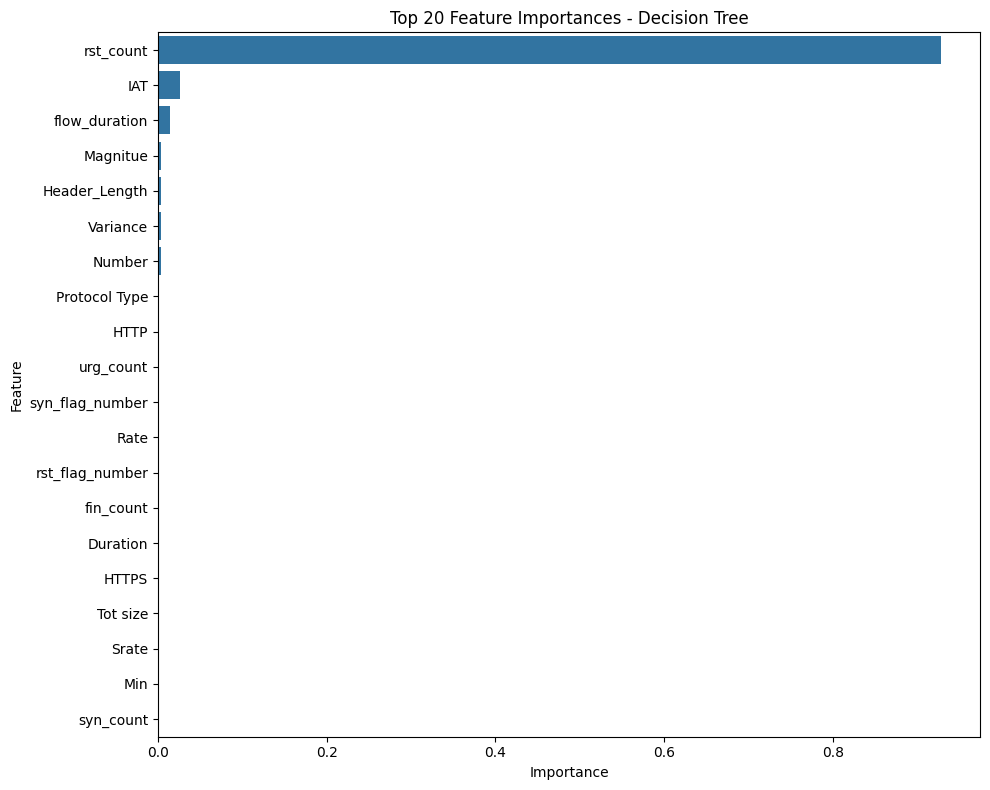

,Feature,Importance
18,rst_count,0.189437
17,urg_count,0.123529
44,Variance,0.082929
41,Magnitue,0.069832
42,Radius,0.066586
36,AVG,0.058751
37,Std,0.044574
0,flow_duration,0.043179
1,Header_Length,0.041348
38,Tot size,0.041288


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/feature_importance_Random_Forest.png


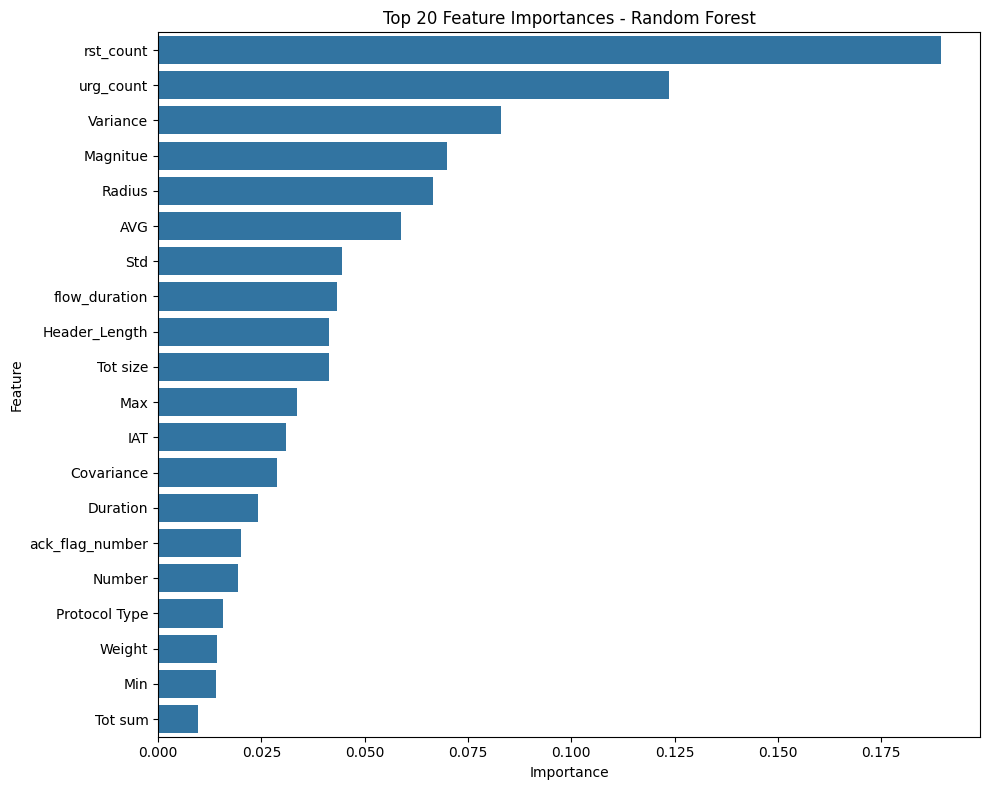

In [33]:
#-------------- Feature importance from tree-based models ---------------#

for model_name in ["Decision Tree", "Random Forest"]:
    clf = ml_models[model_name]
    if hasattr(clf, "feature_importances_"):
        importance_df = pd.DataFrame({
            "Feature": FEATURE_COLUMNS,
            "Importance": clf.feature_importances_
        }).sort_values("Importance", ascending=False)

        importance_df.to_csv(os.path.join(TABLE_DIR, f"feature_importance_{model_name.replace(' ', '_')}.csv"), index=False)
        display(importance_df.head(20))

        plt.figure(figsize=(10, 8))
        sns.barplot(data=importance_df.head(20), x="Importance", y="Feature")
        plt.title(f"Top 20 Feature Importances - {model_name}")
        save_fig(f"feature_importance_{model_name.replace(' ', '_')}.png")


## 13. Final Model Comparison

In [34]:
#-------------- Combined comparison table ---------------#

deep_results = [cnn_results, lstm_results, cnn_lstm_results]
comparison_df = pd.DataFrame(deep_results + ml_results)

metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "Specificity", "FAR", "FNR", "ROC-AUC", "PR-AUC", "Training Time (s)", "Inference Time (s)"]
comparison_display = comparison_df[["Model"] + metric_cols].copy()

comparison_display.to_csv(os.path.join(TABLE_DIR, "all_model_comparison_results.csv"), index=False)
display(comparison_display)

print("Best model by F1 Score:")
display(comparison_display.sort_values("F1 Score", ascending=False).head(1))

print("Best model by ROC-AUC:")
display(comparison_display.sort_values("ROC-AUC", ascending=False).head(1))


,Model,Accuracy,Precision,Recall,F1 Score,Specificity,FAR,FNR,ROC-AUC,PR-AUC,Training Time (s),Inference Time (s)
0,CNN Only,0.984094,0.999980,0.983734,0.991791,0.999161,0.000839,0.016266,0.996160,0.999909,262.889444,4.576765
1,LSTM Only,0.985219,0.999968,0.984898,0.992376,0.998658,0.001342,0.015102,0.996833,0.999925,472.759392,8.560030
2,Bayesian CNN-LSTM,0.985074,0.999996,0.984722,0.992300,0.999832,0.000168,0.015278,0.996278,0.999912,1642.819743,15.020689
3,Logistic Regression,0.975113,0.999919,0.974592,0.987093,0.996744,0.003256,0.025408,0.993794,0.999851,7.297142,0.027905
4,Gaussian Naive Bayes,0.773703,0.999956,0.768280,0.868941,0.998584,0.001416,0.231720,0.992178,0.999794,0.207270,0.168317
5,Decision Tree,0.995737,0.997615,0.998020,0.997817,0.901048,0.098952,0.001980,0.949534,0.997573,4.602397,0.016037
6,Random Forest,0.996910,0.998528,0.998307,0.998418,0.938986,0.061014,0.001693,0.999593,0.999990,25.650570,0.390614
7,Hist Gradient Boosting,0.995980,0.998541,0.997341,0.997940,0.939553,0.060447,0.002659,0.999352,0.999984,6.469641,1.966381


Best model by F1 Score:


,Model,Accuracy,Precision,Recall,F1 Score,Specificity,FAR,FNR,ROC-AUC,PR-AUC,Training Time (s),Inference Time (s)
6,Random Forest,0.99691,0.998528,0.998307,0.998418,0.938986,0.061014,0.001693,0.999593,0.99999,25.65057,0.390614


Best model by ROC-AUC:


,Model,Accuracy,Precision,Recall,F1 Score,Specificity,FAR,FNR,ROC-AUC,PR-AUC,Training Time (s),Inference Time (s)
6,Random Forest,0.99691,0.998528,0.998307,0.998418,0.938986,0.061014,0.001693,0.999593,0.99999,25.65057,0.390614


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/all_model_metric_comparison.png


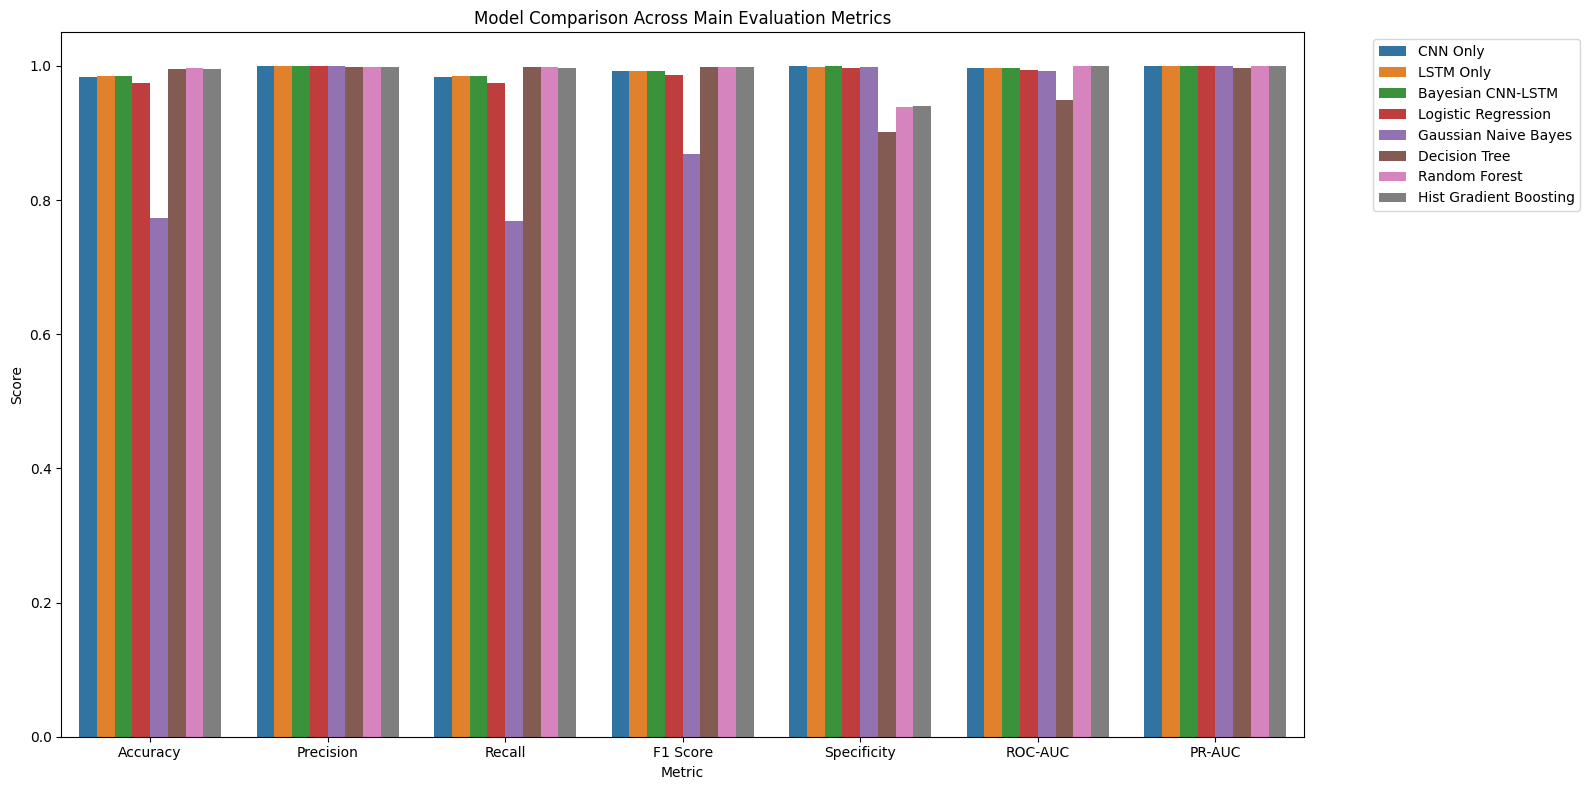

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/models_ranked_by_f1_score.png


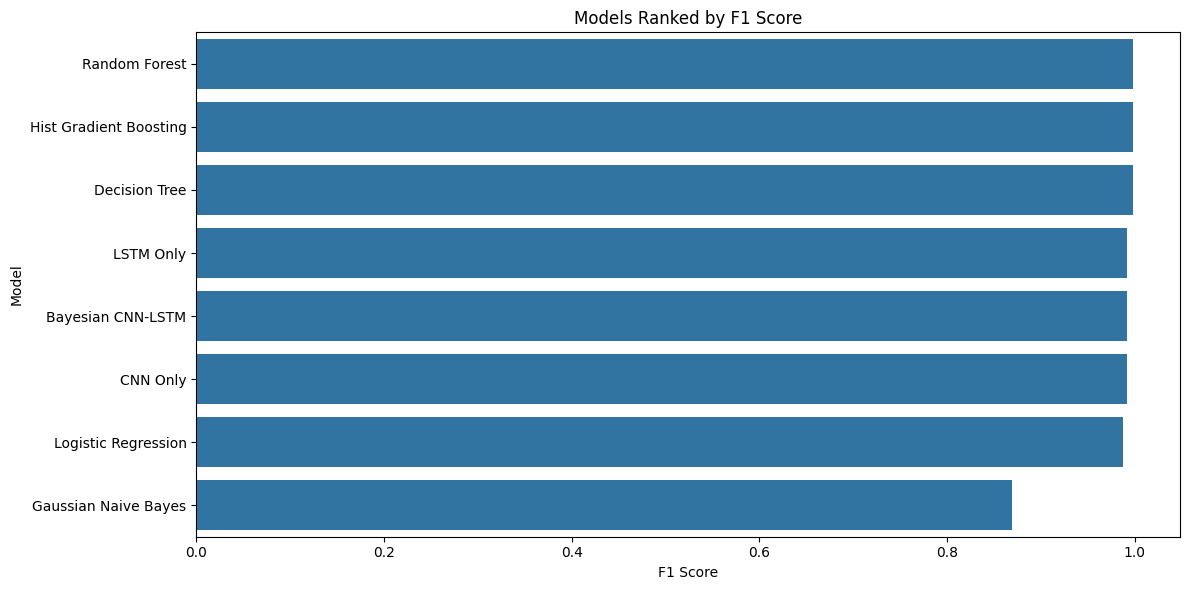

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/models_ranked_by_false_alarm_rate.png


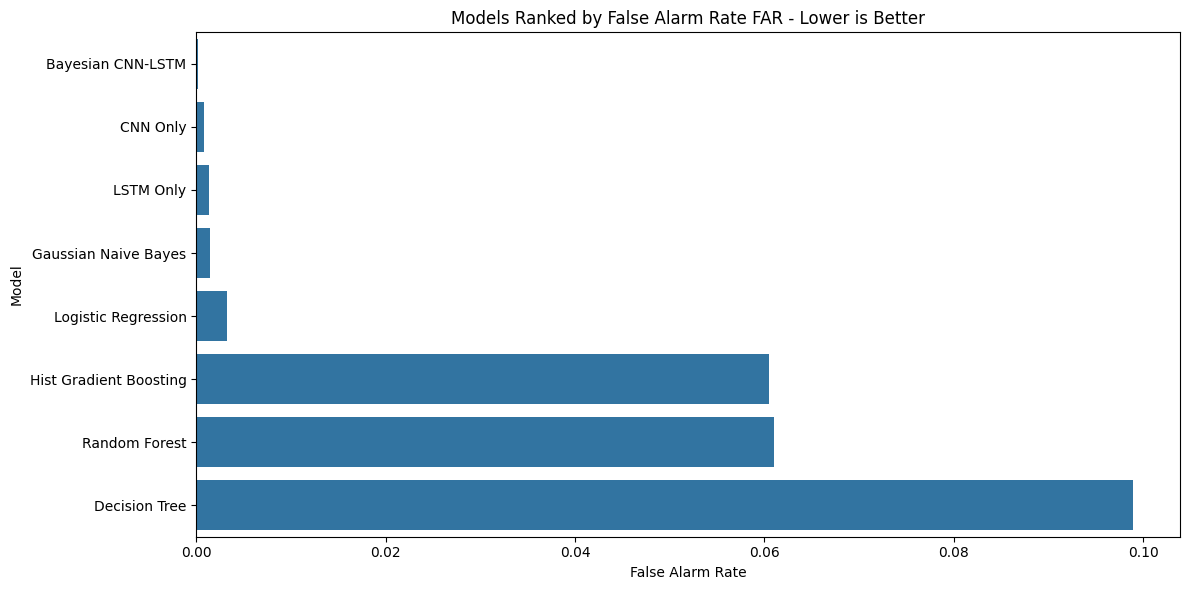

Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/training_time_comparison.png


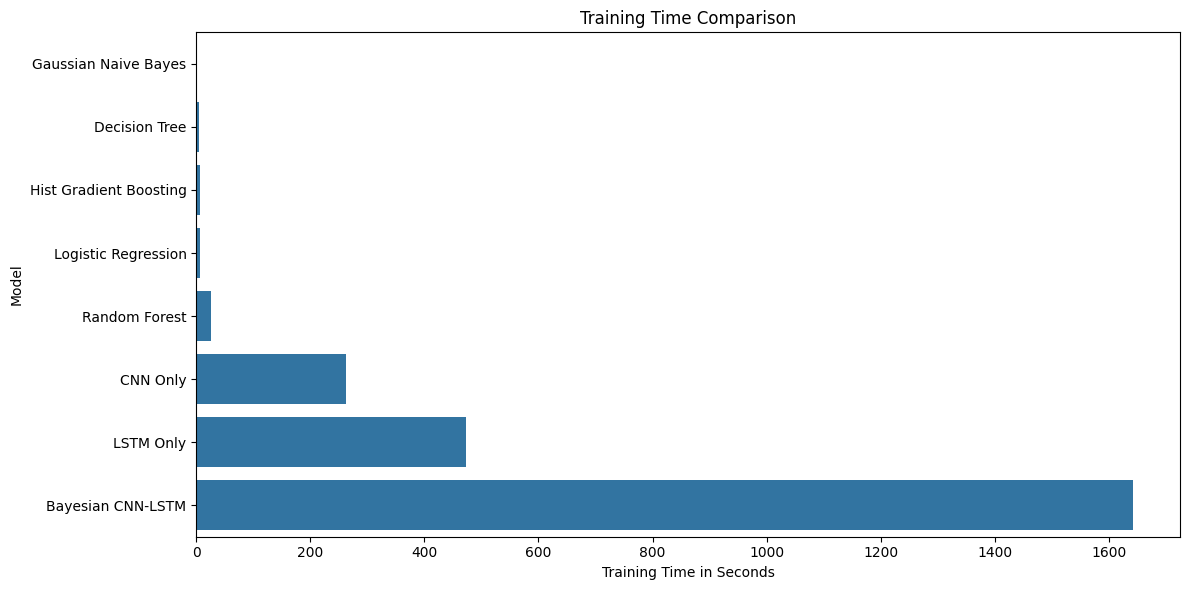

In [35]:
#-------------- Comparison plots ---------------#

plot_metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "Specificity", "ROC-AUC", "PR-AUC"]
comparison_melted = comparison_display.melt(id_vars="Model", value_vars=plot_metrics, var_name="Metric", value_name="Score")

plt.figure(figsize=(16, 8))
sns.barplot(data=comparison_melted, x="Metric", y="Score", hue="Model")
plt.title("Model Comparison Across Main Evaluation Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
save_fig("all_model_metric_comparison.png")

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_display.sort_values("F1 Score", ascending=False), x="F1 Score", y="Model")
plt.title("Models Ranked by F1 Score")
plt.xlabel("F1 Score")
plt.ylabel("Model")
save_fig("models_ranked_by_f1_score.png")

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_display.sort_values("FAR", ascending=True), x="FAR", y="Model")
plt.title("Models Ranked by False Alarm Rate FAR - Lower is Better")
plt.xlabel("False Alarm Rate")
plt.ylabel("Model")
save_fig("models_ranked_by_false_alarm_rate.png")

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_display.sort_values("Training Time (s)", ascending=True), x="Training Time (s)", y="Model")
plt.title("Training Time Comparison")
plt.xlabel("Training Time in Seconds")
plt.ylabel("Model")
save_fig("training_time_comparison.png")


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/roc_curves_all_models.png


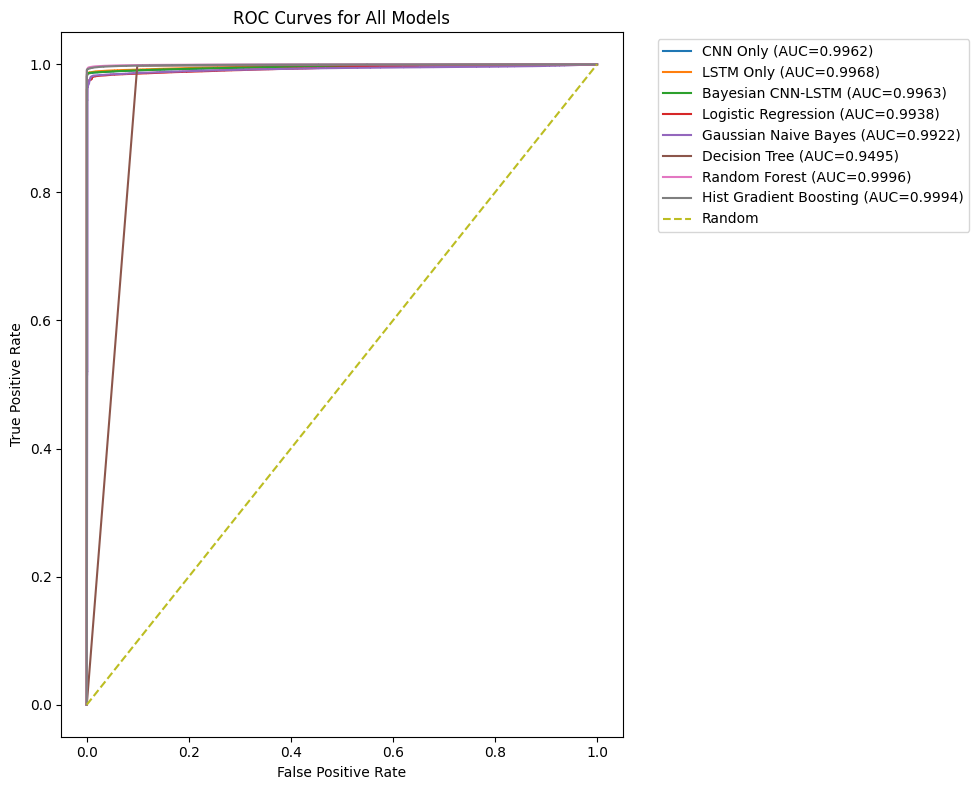

In [36]:
#-------------- ROC curves for all models ---------------#

plt.figure(figsize=(10, 8))

# Deep models
for name, y_true, y_prob in [
    ("CNN Only", y_true_cnn, y_prob_cnn),
    ("LSTM Only", y_true_lstm, y_prob_lstm),
    ("Bayesian CNN-LSTM", y_true_cnn_lstm, y_prob_cnn_lstm)
]:
    try:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc_val = roc_auc_score(y_true, y_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})")
    except Exception as e:
        print(f"Skipping ROC for {name}: {e}")

# ML models
for name, pred_data in ml_predictions.items():
    y_true = pred_data["y_true"]
    y_prob = pred_data["y_prob"]
    if y_prob is not None:
        try:
            fpr, tpr, _ = roc_curve(y_true, y_prob)
            auc_val = roc_auc_score(y_true, y_prob)
            plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})")
        except Exception as e:
            print(f"Skipping ROC for {name}: {e}")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.title("ROC Curves for All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
save_fig("roc_curves_all_models.png")


Saved figure: /kaggle/working/ciciot2023_thesis_outputs/figures/precision_recall_curves_all_models.png


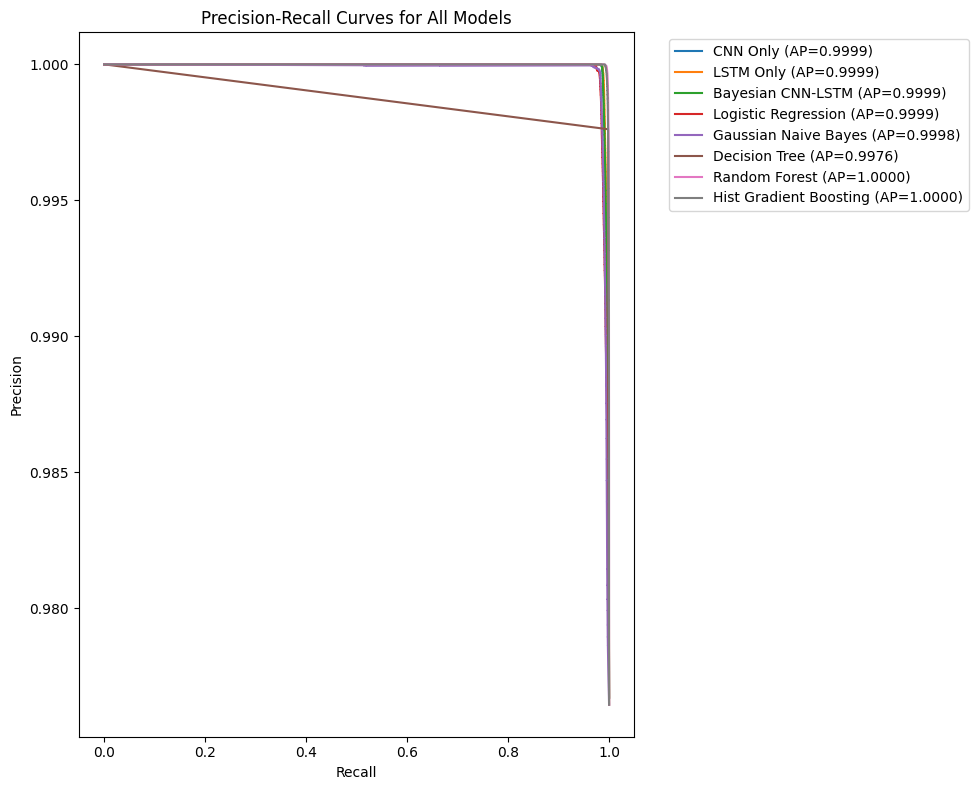

In [37]:
#-------------- Precision-Recall curves for all models ---------------#

plt.figure(figsize=(10, 8))

for name, y_true, y_prob in [
    ("CNN Only", y_true_cnn, y_prob_cnn),
    ("LSTM Only", y_true_lstm, y_prob_lstm),
    ("Bayesian CNN-LSTM", y_true_cnn_lstm, y_prob_cnn_lstm)
]:
    try:
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        ap_val = average_precision_score(y_true, y_prob)
        plt.plot(recall, precision, label=f"{name} (AP={ap_val:.4f})")
    except Exception as e:
        print(f"Skipping PR curve for {name}: {e}")

for name, pred_data in ml_predictions.items():
    y_true = pred_data["y_true"]
    y_prob = pred_data["y_prob"]
    if y_prob is not None:
        try:
            precision, recall, _ = precision_recall_curve(y_true, y_prob)
            ap_val = average_precision_score(y_true, y_prob)
            plt.plot(recall, precision, label=f"{name} (AP={ap_val:.4f})")
        except Exception as e:
            print(f"Skipping PR for {name}: {e}")

plt.title("Precision-Recall Curves for All Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
save_fig("precision_recall_curves_all_models.png")


In [38]:
#-------------- Thesis interpretation helper table ---------------#

interpretation_rows = [
    {
        "Model Type": "CNN Only",
        "Purpose in Thesis": "Tests whether local temporal feature patterns alone are enough for CICIOT2023 attack detection.",
        "Limitation": "CNN does not explicitly model long-term sequence dependency."
    },
    {
        "Model Type": "LSTM Only",
        "Purpose in Thesis": "Tests whether sequence memory alone is enough for attack detection.",
        "Limitation": "LSTM may miss local packet/flow feature motifs captured by convolution."
    },
    {
        "Model Type": "Bayesian CNN-LSTM",
        "Purpose in Thesis": "Main proposed hybrid model that combines CNN local pattern extraction with LSTM temporal dependency modeling, optimized by Bayesian search.",
        "Limitation": "Higher computational cost than standalone and classical ML models."
    },
    {
        "Model Type": "Classical ML Baselines",
        "Purpose in Thesis": "Provides non-deep-learning comparison to justify the need for deep and hybrid architectures.",
        "Limitation": "Usually works on flat feature vectors and does not directly model sequence-level behavior."
    }
]

interpretation_df = pd.DataFrame(interpretation_rows)
interpretation_df.to_csv(os.path.join(TABLE_DIR, "thesis_model_interpretation_table.csv"), index=False)
display(interpretation_df)


,Model Type,Purpose in Thesis,Limitation
0,CNN Only,Tests whether local temporal feature patterns ...,CNN does not explicitly model long-term sequen...
1,LSTM Only,Tests whether sequence memory alone is enough ...,LSTM may miss local packet/flow feature motifs...
2,Bayesian CNN-LSTM,Main proposed hybrid model that combines CNN l...,Higher computational cost than standalone and ...
3,Classical ML Baselines,Provides non-deep-learning comparison to justi...,Usually works on flat feature vectors and does...


## 14. Save All Outputs

In [39]:
#-------------- Save models, scaler, results, and configuration ---------------#

# Save PyTorch model weights
torch.save(cnn_model.state_dict(), os.path.join(MODEL_DIR, "cnn_only_ciciot2023.pt"))
torch.save(lstm_model.state_dict(), os.path.join(MODEL_DIR, "lstm_only_ciciot2023.pt"))
torch.save(cnn_lstm_model.state_dict(), os.path.join(MODEL_DIR, "bayesian_cnn_lstm_ciciot2023.pt"))

# Save scaler
joblib.dump(scaler, os.path.join(MODEL_DIR, "minmax_scaler_ciciot2023.joblib"))

# Save best hyperparameters
best_params_df = pd.DataFrame([best_params])
best_params_df.to_csv(os.path.join(TABLE_DIR, "best_cnn_lstm_hyperparameters.csv"), index=False)

# Save final comparison table
comparison_display.to_csv(os.path.join(TABLE_DIR, "final_model_comparison.csv"), index=False)

# Save configuration
config = {
    "RUN_MODE": RUN_MODE,
    "SEQ_LEN": SEQ_LEN,
    "BATCH_SIZE": BATCH_SIZE,
    "OPTUNA_TRIALS": OPTUNA_TRIALS,
    "OPTUNA_EPOCHS": OPTUNA_EPOCHS,
    "CNN_EPOCHS": CNN_EPOCHS,
    "LSTM_EPOCHS": LSTM_EPOCHS,
    "FINAL_CNN_LSTM_EPOCHS": FINAL_CNN_LSTM_EPOCHS,
    "OPTUNA_MAX_TRAIN_BATCHES": OPTUNA_MAX_TRAIN_BATCHES,
    "FINAL_MAX_TRAIN_BATCHES_PER_EPOCH": FINAL_MAX_TRAIN_BATCHES_PER_EPOCH,
    "MAX_EVAL_BATCHES": MAX_EVAL_BATCHES,
    "ML_TRAIN_SAMPLE_SIZE": ML_TRAIN_SAMPLE_SIZE,
    "ML_TEST_SAMPLE_SIZE": ML_TEST_SAMPLE_SIZE,
    "FEATURE_COLUMNS": FEATURE_COLUMNS,
    "LABEL_COLUMN": LABEL_COLUMN,
    "BENIGN_LABEL": BENIGN_LABEL,
    "BEST_PARAMS": best_params
}

with open(os.path.join(OUTPUT_DIR, "experiment_config.json"), "w") as f:
    json.dump(config, f, indent=4)

print("Saved output directory:", OUTPUT_DIR)
print("Saved figures directory:", FIGURE_DIR)
print("Saved models directory:", MODEL_DIR)
print("Saved tables directory:", TABLE_DIR)


Saved output directory: /kaggle/working/ciciot2023_thesis_outputs
Saved figures directory: /kaggle/working/ciciot2023_thesis_outputs/figures
Saved models directory: /kaggle/working/ciciot2023_thesis_outputs/models
Saved tables directory: /kaggle/working/ciciot2023_thesis_outputs/tables


In [40]:
#-------------- Create ZIP file for easy download from Kaggle ---------------#

zip_output_path = "/kaggle/working/ciciot2023_thesis_outputs.zip"

if os.path.exists(zip_output_path):
    os.remove(zip_output_path)

import shutil
shutil.make_archive("/kaggle/working/ciciot2023_thesis_outputs", "zip", OUTPUT_DIR)

print("Created ZIP file:", zip_output_path)
print("You can download this ZIP from Kaggle output files.")


Created ZIP file: /kaggle/working/ciciot2023_thesis_outputs.zip
You can download this ZIP from Kaggle output files.
